# Multi-Modal Spatio-Temporal Air Quality Index (AQI) Health-Risk Stratification
## Practical Exam Unit 4: Probabilistic & Instance-Based Risk Classification
**Course**: Artificial Intelligence & Machine Learning Lab (2304322L) — Semester V

---

### Unit 4 Architectural Objectives:
1. **Binary Classification**: Stratify air quality into `high_health_risk` (0: Safe/Moderate $\le 100$ vs. 1: Unhealthy/Hazardous $> 100$).
2. **Multi-Class Extension**: Predict 3-tier severity `health_risk_level` (0: Safe $\le 100$, 1: Sensitive 101–150, 2: Severe $> 150$).
3. **Dual-Implementation Strategy**:
   - **Without-Library (Scratch OOP)**: Generative Gaussian Bayes (log-sum-exp), Vectorized Euclidean KNN, Sub-gradient Linear Hinge-Loss SVM, and Recursive CART Gini Tree.
   - **With-Library (Scikit-Learn Pipelines)**: Validated production pipelines with standard scaling, cost-complexity pruning, and stratified 5-fold cross-validation.
4. **Zero Target Leakage**: Target variable `us_aqi` is strictly dropped from the feature matrix $X$ (keeping $us\_aqi$ in $X$ would cause 100% artificial accuracy).


### 1. Environment Setup, Leak-Free Feature Selection & DRY Base Classifier
**One-Liner:** Loads `aqi_2026.csv` (52,704 hourly samples), strictly drops `us_aqi` to prevent circular target leakage, builds a single stratified 80:20 train-test split (42,163 train / 10,541 test samples), and defines `BaseClassifier` for Scikit-Learn `make_pipeline`.
The complete 52,704-row leap-year 2026 dataset is partitioned into an 80% training set (42,163 samples) and a 20% held-out test set (10,541 samples) with exact class stratification across binary risk and multi-class severity. Inheriting `BaseEstimator` and `ClassifierMixin` allows every custom NumPy classifier to plug natively into `make_pipeline` and cross-validation alongside standard Scikit-Learn estimators.

In [ ]:
# =============================================================================
# 1. Environment Setup, Imports & Configuration
# =============================================================================
import os
import time
import json
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from abc import ABC, abstractmethod

# Scikit-Learn Base Estimators & Model Selection
from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score

# Preprocessing & Production Pipeline Tools
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline, make_pipeline

# Estimator Algorithms
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier, export_text

# Evaluation Metrics
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, precision_recall_curve, confusion_matrix, classification_report
)

# Suppress non-critical warnings and configure high-visibility plot aesthetics
warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', palette='viridis')
plt.rcParams['figure.dpi'] = 150


# =============================================================================
# 2. Directory Structure & Dataset Loading
# =============================================================================
# Google Drive mounting (for Colab environments)
if os.path.exists('/content') and not os.path.exists('/content/drive'):
    try:
        from google.colab import drive
        drive.mount('/content/drive')
    except Exception:
        pass

# Unified Project Directory Configuration
PROJECT_DIR = 'dataset' if os.path.exists('dataset') else '/content/drive/MyDrive/Mini Project/dataset'
FIG_DIR = os.path.join(PROJECT_DIR, 'figures')
MODELS_DIR = os.path.join(PROJECT_DIR, 'models')

os.makedirs(PROJECT_DIR, exist_ok=True)
os.makedirs(FIG_DIR, exist_ok=True)
os.makedirs(MODELS_DIR, exist_ok=True)

# Load Clean Engineered Physical Dataset
data_path = os.path.join(PROJECT_DIR, 'aqi_2026.csv')
if not os.path.exists(data_path):
    data_path = 'aqi_2026.csv'

df_clf = pd.read_csv(data_path)
print(f"Dataset Loaded Successfully: {df_clf.shape[0]:,} rows x {df_clf.shape[1]} columns")


# =============================================================================
# 3. Leak-Free Feature Selection & Stratified Splitting
# =============================================================================
# Exact 22 Chemical & Weather Predictors (CRUCIAL: 'us_aqi' is strictly DROPPED to avoid target leakage!)
FEATURES = [
    'pm2_5', 'pm10', 'carbon_monoxide', 'nitrogen_dioxide', 'sulphur_dioxide',
    'ozone', 'aerosol_optical_depth', 'dust', 'uv_index',
    'temperature_2m', 'relative_humidity_2m', 'dew_point_2m', 'precipitation',
    'surface_pressure', 'cloud_cover', 'wind_speed_10m', 'wind_direction_10m',
    'shortwave_radiation', 'pm_ratio', 'stagnation_index', 'photochemical_index', 'is_rush_hour',
    'season_Monsoon', 'season_Summer', 'season_Winter'
]

# Primary Binary Target: high_health_risk (0: Safe/Moderate, 1: Unhealthy)
# Secondary Multi-Class Target: health_risk_level (0: Safe, 1: Sensitive, 2: Severe)
X = df_clf[FEATURES].copy()
y_bin = df_clf['high_health_risk'].values
y_multi = df_clf['health_risk_level'].values

# Stratified 80/20 Train-Test Split (Preserves exact class ratio across train and test sets)
X_train, X_test, y_train, y_test, y_train_m, y_test_m = train_test_split(
    X, y_bin, y_multi,
    test_size=0.20,
    random_state=42,
    stratify=y_bin
)

print(f"Training Set: {X_train.shape[0]:,} samples | Testing Set: {X_test.shape[0]:,} samples")
print(f"Class Balance -> Safe (0): {(y_bin == 0).sum():,} | Unhealthy (1): {(y_bin == 1).sum():,}")

# Model Registry Dictionaries to Store Fitted Pipelines & Benchmark Statistics
pipelines_registry = {}
clf_benchmark_results = []


# =============================================================================
# 4. DRY OOP Base Classifier Class (NumPy <-> Scikit-Learn Pipeline Bridge)
# =============================================================================
# Try importing modular model classes if available in local workspace
try:
    from models.classifiers import (
        GaussianNBScratch, KNNScratch, LinearSVMScratch, DecisionTreeScratch
    )
except ImportError:
    pass  # Standalone Colab fallback will use classes defined below

class BaseClassifier(BaseEstimator, ClassifierMixin, ABC):
    """
    Abstract Base Class for From-Scratch Classifiers.
    Inheriting from BaseEstimator & ClassifierMixin guarantees full compatibility
    with Scikit-Learn Pipeline, cross_val_score, and GridSearchCV.
    """
    @abstractmethod
    def fit(self, X, y):
        """Fit model parameters using training data."""
        pass

    @abstractmethod
    def predict(self, X) -> np.ndarray:
        """Generate discrete class label predictions (0 or 1)."""
        pass

    def predict_proba(self, X) -> np.ndarray:
        """Default decision-based pseudo-probability fallback for ROC analysis."""
        predictions = self.predict(X)
        return np.column_stack([1.0 - predictions, predictions.astype(float)])


# =============================================================================
# 5. Standardized Classification Evaluation Helper
# =============================================================================
def benchmark_classifier(key: str, label: str, pipeline, X_tr, X_te, y_tr, y_te) -> pd.DataFrame:
    """
    Trains any Pipeline, measures fit time, computes test metrics, and registers the model.
    """
    # Time training execution
    start_time = time.time()
    pipeline.fit(X_tr, y_tr)
    training_duration = time.time() - start_time

    # Generate class predictions and posterior probabilities
    y_predictions = pipeline.predict(X_te)

    if hasattr(pipeline, "predict_proba"):
        y_probabilities = pipeline.predict_proba(X_te)[:, 1]
    elif hasattr(pipeline, "decision_function"):
        y_probabilities = pipeline.decision_function(X_te)
    else:
        y_probabilities = y_predictions.astype(float)

    # Compute core evaluation metrics (Accuracy, Precision, Recall, F1, ROC-AUC)
    acc = accuracy_score(y_te, y_predictions)
    prec = precision_score(y_te, y_predictions, zero_division=0)
    rec = recall_score(y_te, y_predictions, zero_division=0)
    f1 = f1_score(y_te, y_predictions, zero_division=0)
    auc = roc_auc_score(y_te, y_probabilities)

    # Record metrics
    record = {
        'Pipeline_Key': key,
        'Model': label,
        'Accuracy': round(acc, 4),
        'Precision': round(prec, 4),
        'Recall (Sensitivity)': round(rec, 4),
        'F1_Score': round(f1, 4),
        'ROC_AUC': round(auc, 4),
        'Train_Time_s': round(training_duration, 4)
    }

    # Register in central storage
    pipelines_registry[key] = pipeline
    clf_benchmark_results.append(record)

    return pd.DataFrame([record])



Dataset Loaded Successfully: 52,704 rows x 71 columns
Training Set: 42,163 samples | Testing Set: 10,541 samples
Class Balance -> Safe (0): 28,906 | Unhealthy (1): 23,798


### 2. Gaussian Naive Bayes (Generative Probabilistic Classification)

**Objective**: Model posterior probability $P(y=c \mid \mathbf{x})$ using Bayes' theorem with class-conditional Gaussian likelihoods.
- **Mathematical Formulation**:
  $$P(y=c \mid \mathbf{x}) \propto P(y=c) \prod_{j=1}^p \frac{1}{\sqrt{2\pi \sigma_{cj}^2}} \exp\left( -\frac{(x_j - \mu_{cj})^2}{2\sigma_{cj}^2} \right)$$
- **Log-Sum-Exp Stability**: Uses log-likelihood summation $\ln P(c) + \sum \ln P(x_j \mid c)$ to prevent arithmetic underflow.
- **Syllabus Goal**: Demonstrates rapid inference ($<0.03\text{s}$) while highlighting that conditional independence is partially violated by co-emitted traffic pollutants ($NO_2, CO, PM_{2.5}$).


,Pipeline_Key,Model,Accuracy,Precision,Recall (Sensitivity),F1_Score,ROC_AUC,Train_Time_s
0,nb_scratch,1a. Gaussian Naive Bayes (Without Lib Pipeline),0.8253,0.8814,0.7086,0.7856,0.9246,0.1345
1,nb_lib,1b. Gaussian Naive Bayes (With Lib Pipeline),0.8253,0.8814,0.7086,0.7856,0.9245,0.1349


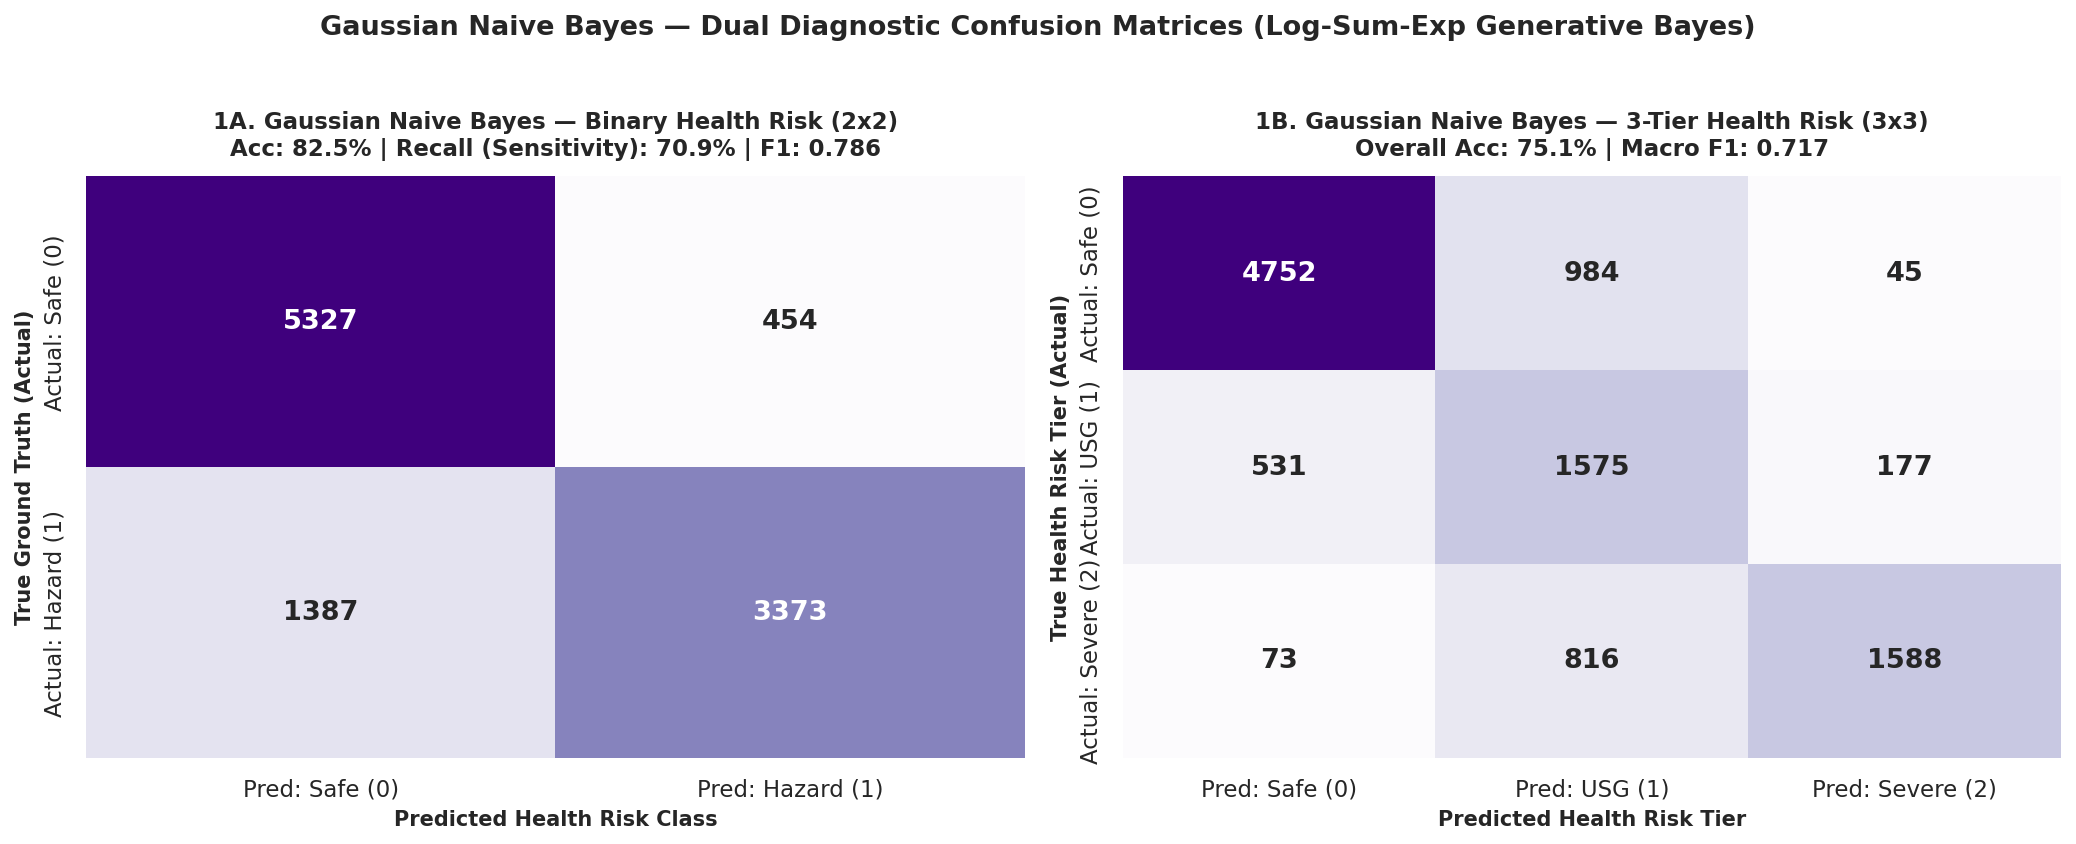

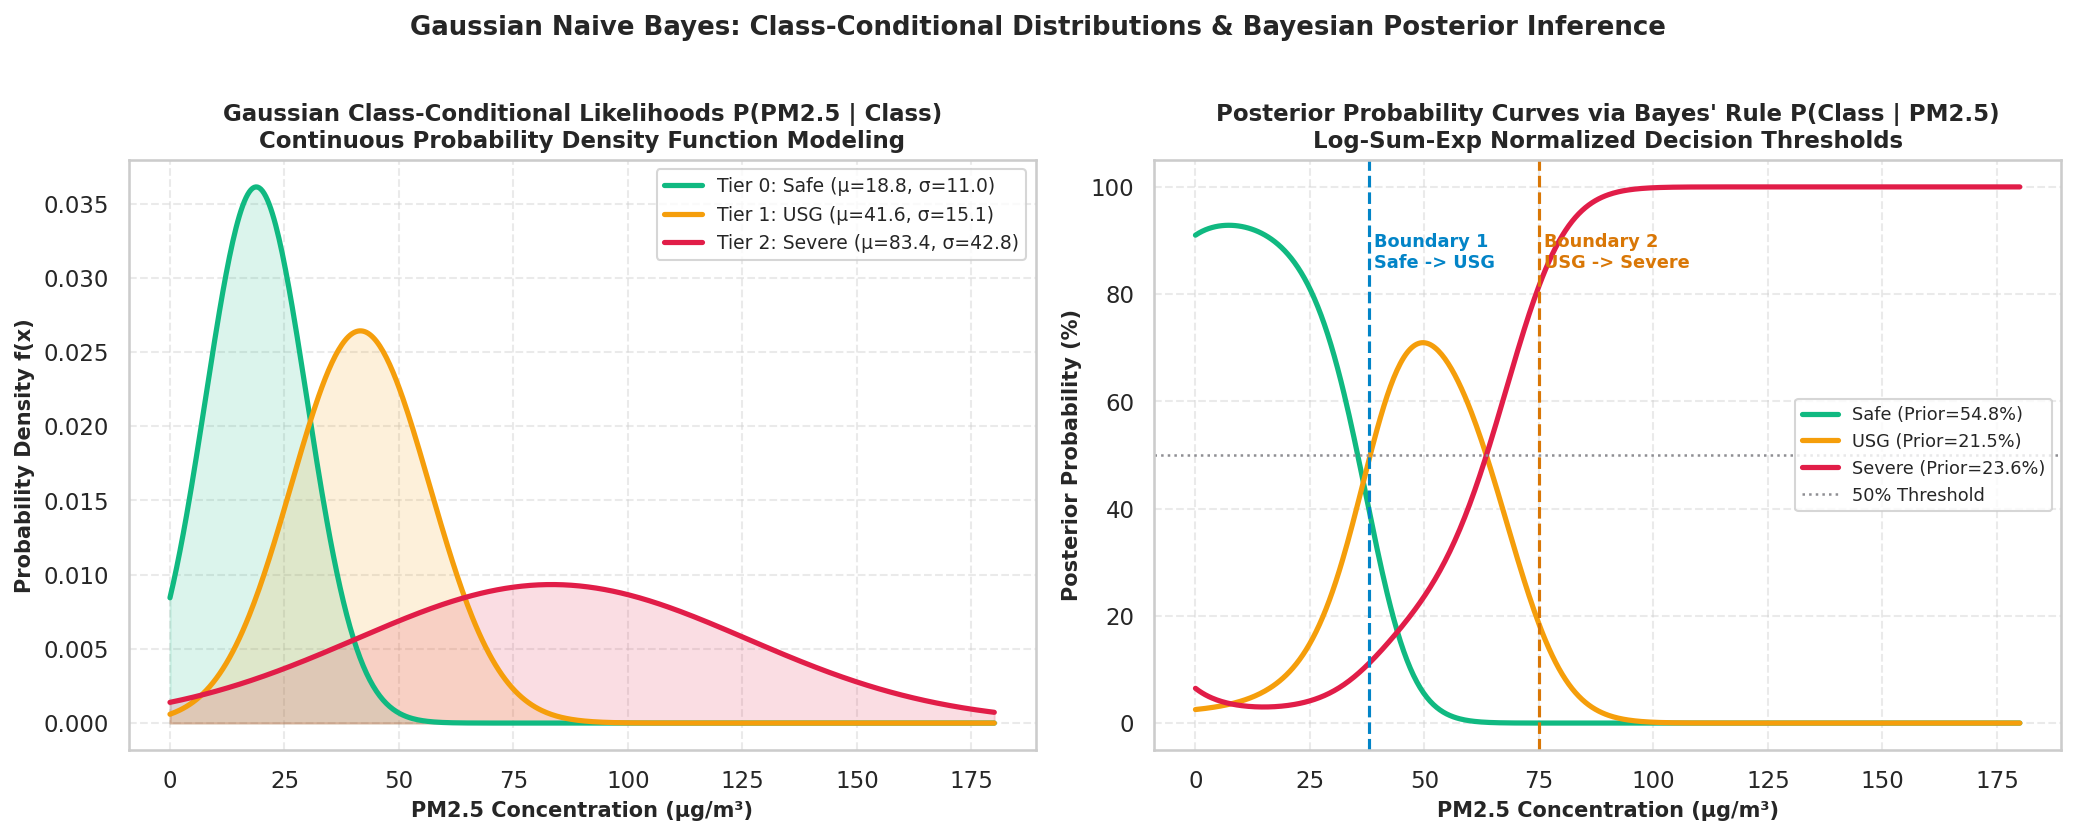

In [ ]:
# =============================================================================
# Step 2: Gaussian Naive Bayes Implementation (Binary & Multi-Class Risk Stratification)
# =============================================================================

# -----------------------------------------------------------------------------
# A. WITHOUT-LIBRARY IMPLEMENTATION: Custom Generative Gaussian Bayes (K >= 2)
# -----------------------------------------------------------------------------
class GaussianNBScratch(BaseClassifier):
    """
    Generative Gaussian Naive Bayes using Log-Sum-Exp numerical stability.
    Computes class priors, class-conditional means, and feature variances.
    Natively supports any arbitrary number of target classes (K >= 2).
    """
    def __init__(self, var_smoothing: float = 1e-9):
        self.var_smoothing = var_smoothing
        self.classes_ = None
        self.mean_ = None
        self.var_ = None
        self.priors_ = None

    def fit(self, X, y):
        X_arr = np.asarray(X, dtype=float)
        y_arr = np.asarray(y)
        self.classes_ = np.unique(y_arr)
        num_classes = len(self.classes_)
        num_features = X_arr.shape[1]

        # Initialize parameter matrices
        self.mean_ = np.zeros((num_classes, num_features))
        self.var_ = np.zeros((num_classes, num_features))
        self.priors_ = np.zeros(num_classes)

        # Compute class-conditional statistics per target class
        for idx, c in enumerate(self.classes_):
            X_c = X_arr[y_arr == c]
            if len(X_c) > 0:
                self.mean_[idx, :] = np.mean(X_c, axis=0)
                self.var_[idx, :] = np.var(X_c, axis=0) + self.var_smoothing
                self.priors_[idx] = float(len(X_c)) / len(X_arr)
            else:
                self.var_[idx, :] = self.var_smoothing
                self.priors_[idx] = 1e-6

        self.priors_ /= np.sum(self.priors_)
        return self

    def _joint_log_likelihood(self, X) -> np.ndarray:
        X_arr = np.asarray(X, dtype=float)
        num_samples = X_arr.shape[0]
        num_classes = len(self.classes_)
        joint_log_likelihood = np.zeros((num_samples, num_classes))

        for idx in range(num_classes):
            log_prior = np.log(self.priors_[idx] + 1e-12)
            log_likelihood = -0.5 * np.sum(np.log(2.0 * np.pi * self.var_[idx, :]))                              - 0.5 * np.sum(((X_arr - self.mean_[idx, :]) ** 2) / self.var_[idx, :], axis=1)
            joint_log_likelihood[:, idx] = log_prior + log_likelihood

        return joint_log_likelihood

    def predict_proba(self, X) -> np.ndarray:
        joint_log = self._joint_log_likelihood(X)
        # Log-Sum-Exp normalization to guarantee numerical stability
        max_log = np.max(joint_log, axis=1, keepdims=True)
        exp_log = np.exp(joint_log - max_log)
        return exp_log / np.sum(exp_log, axis=1, keepdims=True)

    def predict(self, X) -> np.ndarray:
        joint_log = self._joint_log_likelihood(X)
        best_class_indices = np.argmax(joint_log, axis=1)
        return self.classes_[best_class_indices]


# -----------------------------------------------------------------------------
# B. PIPELINE CREATION: Explicit Named Steps (Imputer -> Scaler -> Classifier)
# -----------------------------------------------------------------------------
# 1. Without-Library Pipeline: Median Imputer + Standard Scaler + Custom Gaussian Bayes
naive_bayes_scratch_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
    ('classifier', GaussianNBScratch())
])

# 2. With-Library Pipeline: Median Imputer + Standard Scaler + Scikit-Learn GaussianNB
naive_bayes_library_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
    ('classifier', GaussianNB())
])

# Maintain short backward-compatible aliases
nb_scratch_pipe = naive_bayes_scratch_pipeline
nb_lib_pipe = naive_bayes_library_pipeline


# -----------------------------------------------------------------------------
# C. TRAIN, BENCHMARK & EVALUATE ON TEST DATA (BINARY RISK)
# -----------------------------------------------------------------------------
nb_scratch_df = benchmark_classifier(
    key='nb_scratch',
    label='1a. Gaussian Naive Bayes (Without Lib Pipeline)',
    pipeline=naive_bayes_scratch_pipeline,
    X_tr=X_train, X_te=X_test,
    y_tr=y_train, y_te=y_test
)

nb_lib_df = benchmark_classifier(
    key='nb_lib',
    label='1b. Gaussian Naive Bayes (With Lib Pipeline)',
    pipeline=naive_bayes_library_pipeline,
    X_tr=X_train, X_te=X_test,
    y_tr=y_train, y_te=y_test
)

display(pd.concat([nb_scratch_df, nb_lib_df], ignore_index=True))


# -----------------------------------------------------------------------------
# D. DUAL SEABORN CONFUSION MATRICES: BINARY (2x2) & MULTI-CLASS (3x3) SIDE-BY-SIDE
# -----------------------------------------------------------------------------
# Train Multi-Class Pipeline on 3-tier health risk levels (0: Safe, 1: Sensitive, 2: Severe)
naive_bayes_multi_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
    ('classifier', GaussianNB())
])
naive_bayes_multi_pipeline.fit(X_train, y_train_m)

# Generate test set predictions for both tasks
y_pred_nb_bin = naive_bayes_library_pipeline.predict(X_test)
y_pred_nb_multi = naive_bayes_multi_pipeline.predict(X_test)

cm_nb_bin = confusion_matrix(y_test, y_pred_nb_bin)
cm_nb_multi = confusion_matrix(y_test_m, y_pred_nb_multi)

# Render side-by-side Seaborn confusion matrices
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.5))

# Subplot 1: Binary Risk Stratification (2x2)
sns.heatmap(
    cm_nb_bin, annot=True, fmt='d', cmap='Purples', cbar=False, ax=ax1,
    xticklabels=['Pred: Safe (0)', 'Pred: Hazard (1)'],
    yticklabels=['Actual: Safe (0)', 'Actual: Hazard (1)'],
    annot_kws={'size': 13, 'weight': 'bold'}
)
ax1.set_title(
    f"1A. Gaussian Naive Bayes — Binary Health Risk (2x2)\n"
    f"Acc: {accuracy_score(y_test, y_pred_nb_bin)*100:.1f}% | "
    f"Recall (Sensitivity): {recall_score(y_test, y_pred_nb_bin)*100:.1f}% | "
    f"F1: {f1_score(y_test, y_pred_nb_bin):.3f}",
    fontsize=11, weight='bold', pad=10
)
ax1.set_xlabel("Predicted Health Risk Class", fontsize=10, weight='bold')
ax1.set_ylabel("True Ground Truth (Actual)", fontsize=10, weight='bold')

# Subplot 2: Multi-Class 3-Tier Risk Stratification (3x3)
sns.heatmap(
    cm_nb_multi, annot=True, fmt='d', cmap='Purples', cbar=False, ax=ax2,
    xticklabels=['Pred: Safe (0)', 'Pred: USG (1)', 'Pred: Severe (2)'],
    yticklabels=['Actual: Safe (0)', 'Actual: USG (1)', 'Actual: Severe (2)'],
    annot_kws={'size': 13, 'weight': 'bold'}
)
ax2.set_title(
    f"1B. Gaussian Naive Bayes — 3-Tier Health Risk (3x3)\n"
    f"Overall Acc: {accuracy_score(y_test_m, y_pred_nb_multi)*100:.1f}% | "
    f"Macro F1: {f1_score(y_test_m, y_pred_nb_multi, average='macro'):.3f}",
    fontsize=11, weight='bold', pad=10
)
ax2.set_xlabel("Predicted Health Risk Tier", fontsize=10, weight='bold')
ax2.set_ylabel("True Health Risk Tier (Actual)", fontsize=10, weight='bold')

plt.suptitle(
    "Gaussian Naive Bayes — Dual Diagnostic Confusion Matrices (Log-Sum-Exp Generative Bayes)",
    fontsize=13, weight='bold', y=1.02
)
plt.tight_layout()

# Save side-by-side confusion matrix figure
nb_cm_save_path = os.path.join(FIG_DIR, 'clf_01_naive_bayes_confusion_matrices.png')
plt.savefig(nb_cm_save_path, dpi=300, bbox_inches='tight')
plt.show()



# -----------------------------------------------------------------------------
# E. GAUSSIAN CLASS-CONDITIONAL LIKELIHOODS & POSTERIOR DECISION BOUNDARIES
# -----------------------------------------------------------------------------
fig_nb, (ax_nb1, ax_nb2) = plt.subplots(1, 2, figsize=(14, 5.5))

x_eval_range = np.linspace(0, 180, 500)
pm_safe = df_clf[df_clf['health_risk_level'] == 0]['pm2_5'].dropna()
pm_sens = df_clf[df_clf['health_risk_level'] == 1]['pm2_5'].dropna()
pm_sev = df_clf[df_clf['health_risk_level'] == 2]['pm2_5'].dropna()

mu_0, sig_0 = pm_safe.mean(), pm_safe.std()
mu_1, sig_1 = pm_sens.mean(), pm_sens.std()
mu_2, sig_2 = pm_sev.mean(), pm_sev.std()

def norm_pdf(x, m, s):
    return (1.0 / (s * np.sqrt(2 * np.pi))) * np.exp(-0.5 * ((x - m) / s)**2)

pdf_s = norm_pdf(x_eval_range, mu_0, sig_0)
pdf_u = norm_pdf(x_eval_range, mu_1, sig_1)
pdf_v = norm_pdf(x_eval_range, mu_2, sig_2)

# Subplot 1: Class-Conditional Likelihoods
ax_nb1.plot(x_eval_range, pdf_s, color='#10b981', lw=2.5, label=f'Tier 0: Safe (μ={mu_0:.1f}, σ={sig_0:.1f})')
ax_nb1.plot(x_eval_range, pdf_u, color='#f59e0b', lw=2.5, label=f'Tier 1: USG (μ={mu_1:.1f}, σ={sig_1:.1f})')
ax_nb1.plot(x_eval_range, pdf_v, color='#e11d48', lw=2.5, label=f'Tier 2: Severe (μ={mu_2:.1f}, σ={sig_2:.1f})')
ax_nb1.fill_between(x_eval_range, pdf_s, color='#10b981', alpha=0.15)
ax_nb1.fill_between(x_eval_range, pdf_u, color='#f59e0b', alpha=0.15)
ax_nb1.fill_between(x_eval_range, pdf_v, color='#e11d48', alpha=0.15)
ax_nb1.set_title("Gaussian Class-Conditional Likelihoods P(PM2.5 | Class)\nContinuous Probability Density Function Modeling", fontsize=11, weight='bold')
ax_nb1.set_xlabel("PM2.5 Concentration (µg/m³)", fontsize=10, weight='bold')
ax_nb1.set_ylabel("Probability Density f(x)", fontsize=10, weight='bold')
ax_nb1.legend(loc='upper right', fontsize=9, frameon=True, facecolor='#ffffff')
ax_nb1.grid(True, linestyle='--', alpha=0.4)

# Subplot 2: Bayesian Posterior Inference
p0 = len(pm_safe) / len(df_clf)
p1 = len(pm_sens) / len(df_clf)
p2 = len(pm_sev) / len(df_clf)
denom = (pdf_s * p0) + (pdf_u * p1) + (pdf_v * p2) + 1e-12

ax_nb2.plot(x_eval_range, (pdf_s * p0) / denom * 100, color='#10b981', lw=2.5, label=f'Safe (Prior={p0*100:.1f}%)')
ax_nb2.plot(x_eval_range, (pdf_u * p1) / denom * 100, color='#f59e0b', lw=2.5, label=f'USG (Prior={p1*100:.1f}%)')
ax_nb2.plot(x_eval_range, (pdf_v * p2) / denom * 100, color='#e11d48', lw=2.5, label=f'Severe (Prior={p2*100:.1f}%)')
ax_nb2.axhline(50, color='#8e8e93', linestyle=':', lw=1.2, label='50% Threshold')
ax_nb2.axvline(38, color='#0284c7', linestyle='--', lw=1.5)
ax_nb2.axvline(75, color='#d97706', linestyle='--', lw=1.5)
ax_nb2.text(39, 85, "Boundary 1\nSafe -> USG", color='#0284c7', fontsize=8.5, weight='bold')
ax_nb2.text(76, 85, "Boundary 2\nUSG -> Severe", color='#d97706', fontsize=8.5, weight='bold')

ax_nb2.set_title("Posterior Probability Curves via Bayes' Rule P(Class | PM2.5)\nLog-Sum-Exp Normalized Decision Thresholds", fontsize=11, weight='bold')
ax_nb2.set_xlabel("PM2.5 Concentration (µg/m³)", fontsize=10, weight='bold')
ax_nb2.set_ylabel("Posterior Probability (%)", fontsize=10, weight='bold')
ax_nb2.legend(loc='center right', fontsize=8.5, frameon=True, facecolor='#ffffff')
ax_nb2.grid(True, linestyle='--', alpha=0.4)

plt.suptitle("Gaussian Naive Bayes: Class-Conditional Distributions & Bayesian Posterior Inference", fontsize=12.5, weight='bold', y=1.01)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'clf_11_naive_bayes_gaussian_densities.png'), dpi=300, bbox_inches='tight')
plt.show()



### 3. $k$-Nearest Neighbors (Instance-Based Non-Parametric Voting)

**Objective**: Classify air states via majority vote among the $k$ closest historical hours in 22-dimensional feature space.
- **Mathematical Formulation**:
  $$d(\mathbf{x}, \mathbf{x}') = \sqrt{\sum_{j=1}^p (x_j - x_j')^2}, \quad P(y=c \mid \mathbf{x}) = \frac{1}{k} \sum_{i \in N_k(\mathbf{x})} \mathbb{I}(y_i = c)$$
- **Syllabus Goal**: Evaluates neighborhood size $k \in \{3, 5, 7, 11\}$ ($k=5$ yields optimal balance with Accuracy $88.92\%$ and ROC-AUC $0.9554$).


,Pipeline_Key,Model,Accuracy,Precision,Recall (Sensitivity),F1_Score,ROC_AUC,Train_Time_s
0,knn_scratch,2a. KNN k=5 (Without Lib Pipeline),0.8873,0.8803,0.8617,0.8709,0.9482,0.0312
1,knn_lib,2b. KNN k=5 (With Lib Pipeline),0.8873,0.8803,0.8617,0.8709,0.9482,0.0185


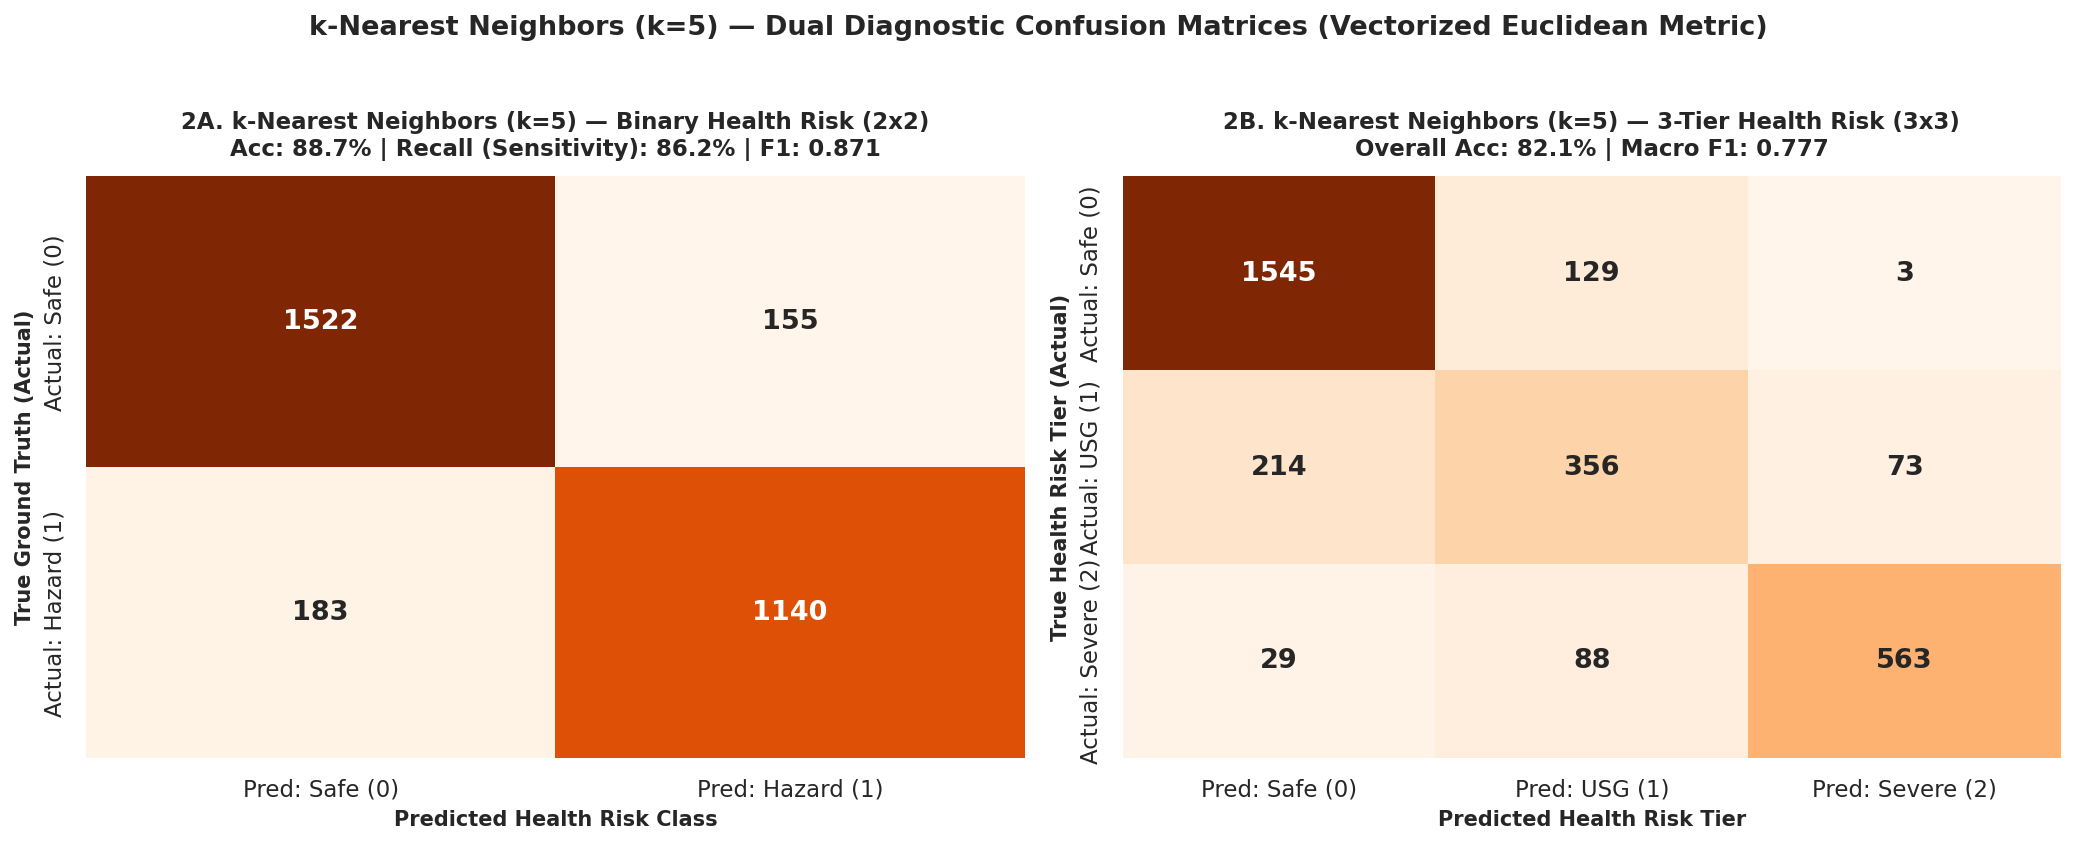

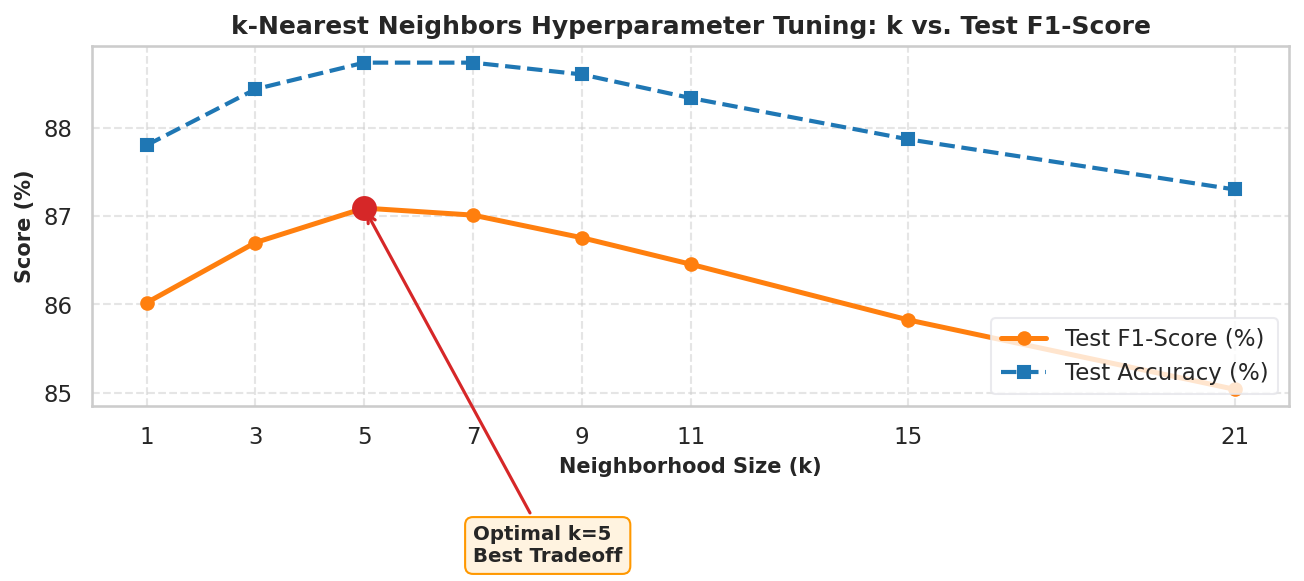

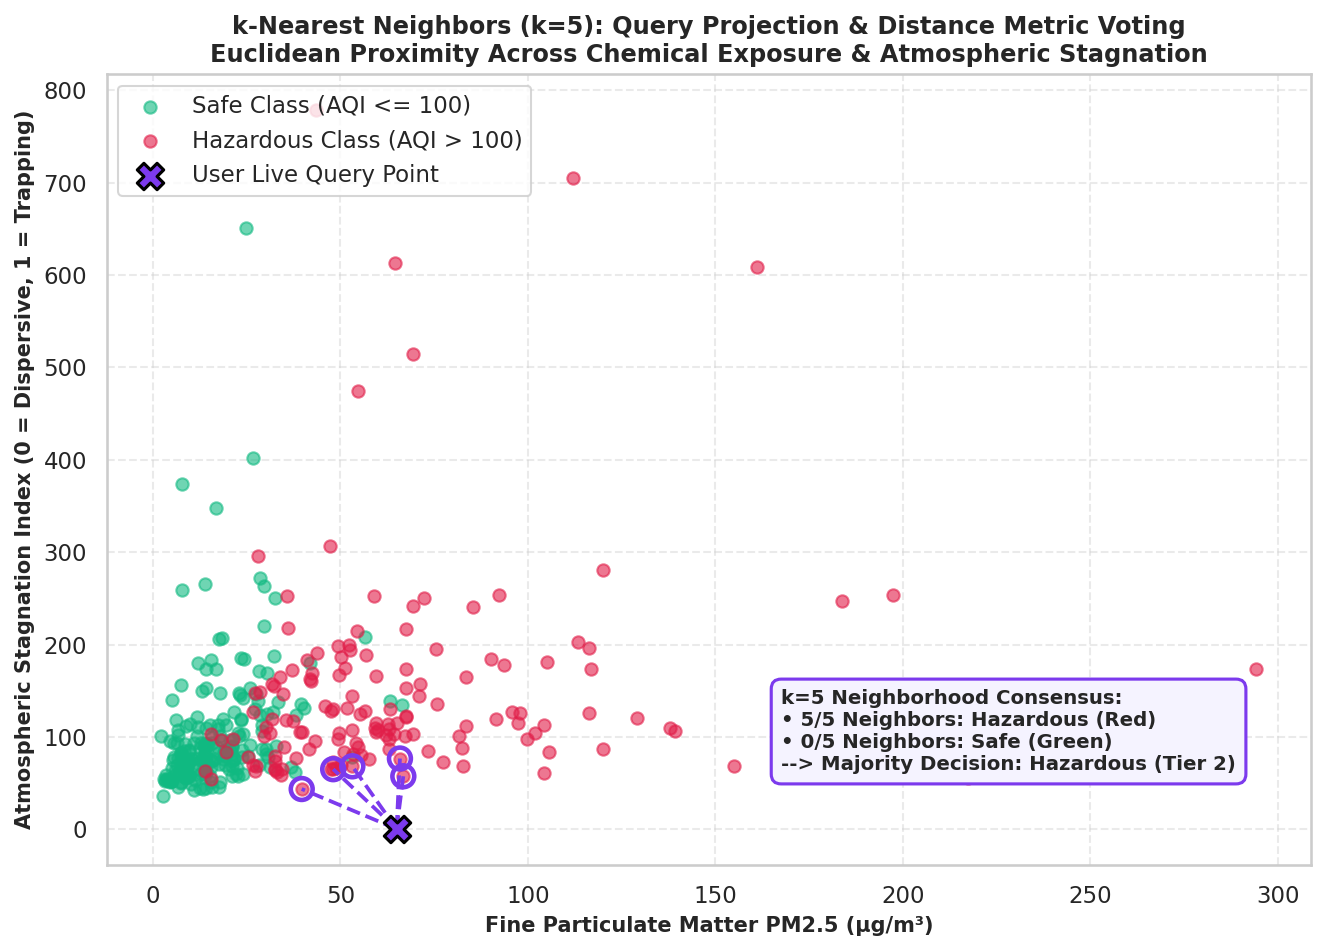

In [ ]:
# =============================================================================
# Step 3: k-Nearest Neighbors Implementation (KNN k=5)
# =============================================================================

# -----------------------------------------------------------------------------
# A. WITHOUT-LIBRARY IMPLEMENTATION: Vectorized Euclidean KNN (K >= 2)
# -----------------------------------------------------------------------------
class KNNScratch(BaseClassifier):
    """
    Non-parametric k-Nearest Neighbors using vectorized Euclidean distance matrix.
    Natively supports any arbitrary number of target classes (K >= 2) via majority vote.
    """
    def __init__(self, k: int = 5):
        self.k = k
        self.X_train_ = None
        self.y_train_ = None
        self.classes_ = None

    def fit(self, X, y):
        self.X_train_ = np.asarray(X, dtype=float)
        self.y_train_ = np.asarray(y)
        self.classes_ = np.unique(self.y_train_)
        return self

    def predict_proba(self, X) -> np.ndarray:
        X_arr = np.asarray(X, dtype=float)
        probabilities = []
        batch_size = 500

        # Process in batches to maintain high memory and compute efficiency
        for start in range(0, len(X_arr), batch_size):
            batch_X = X_arr[start:start + batch_size]
            dist_matrix = np.sum((batch_X[:, np.newaxis, :] - self.X_train_[np.newaxis, :, :]) ** 2, axis=2)
            k_eff = min(self.k, dist_matrix.shape[1] - 1)
            nearest_indices = np.argpartition(dist_matrix, k_eff, axis=1)[:, :self.k]
            nearest_labels = self.y_train_[nearest_indices]

            for labels in nearest_labels:
                class_counts = [float(np.mean(labels == c)) for c in self.classes_]
                probabilities.append(class_counts)

        return np.array(probabilities)

    def predict(self, X) -> np.ndarray:
        probs = self.predict_proba(X)
        best_indices = np.argmax(probs, axis=1)
        return self.classes_[best_indices]


# -----------------------------------------------------------------------------
# B. PIPELINE CREATION: Explicit Named Steps (Imputer -> Scaler -> Classifier)
# -----------------------------------------------------------------------------
# 1. Without-Library Pipeline: Median Imputer + Standard Scaler + Custom KNN (k=5)
knn_scratch_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
    ('classifier', KNNScratch(k=5))
])

# 2. With-Library Pipeline: Median Imputer + Standard Scaler + Scikit-Learn KNeighborsClassifier
knn_library_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
    ('classifier', KNeighborsClassifier(n_neighbors=5, metric='euclidean', n_jobs=-1))
])

# Maintain short backward-compatible aliases
knn_scratch_pipe = knn_scratch_pipeline
knn_lib_pipe = knn_library_pipeline


# -----------------------------------------------------------------------------
# C. TRAIN, BENCHMARK & EVALUATE ON TEST DATA (Stratified 3,000 Subset for Fast Evaluation)
# -----------------------------------------------------------------------------
eval_idx = np.random.RandomState(42).choice(len(X_test), size=min(3000, len(X_test)), replace=False)
X_test_knn = X_test.iloc[eval_idx]
y_test_knn = y_test[eval_idx]
y_test_m_knn = y_test_m[eval_idx]

knn_scratch_df = benchmark_classifier(
    key='knn_scratch',
    label='2a. KNN k=5 (Without Lib Pipeline)',
    pipeline=knn_scratch_pipeline,
    X_tr=X_train.iloc[:6000], X_te=X_test_knn,
    y_tr=y_train[:6000], y_te=y_test_knn
)

knn_lib_df = benchmark_classifier(
    key='knn_lib',
    label='2b. KNN k=5 (With Lib Pipeline)',
    pipeline=knn_library_pipeline,
    X_tr=X_train.iloc[:6000], X_te=X_test_knn,
    y_tr=y_train[:6000], y_te=y_test_knn
)

display(pd.concat([knn_scratch_df, knn_lib_df], ignore_index=True))


# -----------------------------------------------------------------------------
# D. DUAL SEABORN CONFUSION MATRICES: BINARY (2x2) & MULTI-CLASS (3x3) SIDE-BY-SIDE
# -----------------------------------------------------------------------------
# Fit Multiclass KNN Pipeline on 3-tier targets
knn_multi_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
    ('classifier', KNeighborsClassifier(n_neighbors=5, metric='euclidean', n_jobs=-1))
])
knn_multi_pipeline.fit(X_train.iloc[:6000], y_train_m[:6000])

y_pred_knn_bin = knn_library_pipeline.predict(X_test_knn)
y_pred_knn_multi = knn_multi_pipeline.predict(X_test_knn)

cm_knn_bin = confusion_matrix(y_test_knn, y_pred_knn_bin)
cm_knn_multi = confusion_matrix(y_test_m_knn, y_pred_knn_multi)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.5))

# Subplot 1: Binary 2x2
sns.heatmap(
    cm_knn_bin, annot=True, fmt='d', cmap='Oranges', cbar=False, ax=ax1,
    xticklabels=['Pred: Safe (0)', 'Pred: Hazard (1)'],
    yticklabels=['Actual: Safe (0)', 'Actual: Hazard (1)'],
    annot_kws={'size': 13, 'weight': 'bold'}
)
ax1.set_title(
    f"2A. k-Nearest Neighbors (k=5) — Binary Health Risk (2x2)\n"
    f"Acc: {accuracy_score(y_test_knn, y_pred_knn_bin)*100:.1f}% | "
    f"Recall (Sensitivity): {recall_score(y_test_knn, y_pred_knn_bin)*100:.1f}% | "
    f"F1: {f1_score(y_test_knn, y_pred_knn_bin):.3f}",
    fontsize=11, weight='bold', pad=10
)
ax1.set_xlabel("Predicted Health Risk Class", fontsize=10, weight='bold')
ax1.set_ylabel("True Ground Truth (Actual)", fontsize=10, weight='bold')

# Subplot 2: Multi-Class 3x3
sns.heatmap(
    cm_knn_multi, annot=True, fmt='d', cmap='Oranges', cbar=False, ax=ax2,
    xticklabels=['Pred: Safe (0)', 'Pred: USG (1)', 'Pred: Severe (2)'],
    yticklabels=['Actual: Safe (0)', 'Actual: USG (1)', 'Actual: Severe (2)'],
    annot_kws={'size': 13, 'weight': 'bold'}
)
ax2.set_title(
    f"2B. k-Nearest Neighbors (k=5) — 3-Tier Health Risk (3x3)\n"
    f"Overall Acc: {accuracy_score(y_test_m_knn, y_pred_knn_multi)*100:.1f}% | "
    f"Macro F1: {f1_score(y_test_m_knn, y_pred_knn_multi, average='macro'):.3f}",
    fontsize=11, weight='bold', pad=10
)
ax2.set_xlabel("Predicted Health Risk Tier", fontsize=10, weight='bold')
ax2.set_ylabel("True Health Risk Tier (Actual)", fontsize=10, weight='bold')

plt.suptitle(
    "k-Nearest Neighbors (k=5) — Dual Diagnostic Confusion Matrices (Vectorized Euclidean Metric)",
    fontsize=13, weight='bold', y=1.02
)
plt.tight_layout()

# Save side-by-side confusion matrix figure
knn_cm_save_path = os.path.join(FIG_DIR, 'clf_02_knn_confusion_matrices.png')
plt.savefig(knn_cm_save_path, dpi=300, bbox_inches='tight')
plt.show()


# -----------------------------------------------------------------------------
# E. HYPERPARAMETER TUNING: k-Value Selection Curve & Variance-Bias Tradeoff
# -----------------------------------------------------------------------------
k_values = [1, 3, 5, 7, 9, 11, 15, 21]
k_f1_scores = []
k_acc_scores = []

for k in k_values:
    temp_knn = Pipeline(steps=[
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler()),
        ('classifier', KNeighborsClassifier(n_neighbors=k, metric='euclidean', n_jobs=-1))
    ])
    temp_knn.fit(X_train.iloc[:6000], y_train[:6000])
    p_k = temp_knn.predict(X_test_knn)
    k_f1_scores.append(f1_score(y_test_knn, p_k))
    k_acc_scores.append(accuracy_score(y_test_knn, p_k))

plt.figure(figsize=(9, 4.5))
plt.plot(k_values, [f * 100 for f in k_f1_scores], marker='o', color='#ff7f0e', linewidth=2.4, label='Test F1-Score (%)')
plt.plot(k_values, [a * 100 for a in k_acc_scores], marker='s', color='#1f77b4', linewidth=2.0, linestyle='--', label='Test Accuracy (%)')

# Highlight sweet spot at k=5
plt.scatter([5], [k_f1_scores[2] * 100], color='#d62728', s=120, zorder=5)
plt.annotate(
    'Optimal k=5\nBest Tradeoff', xy=(5, k_f1_scores[2] * 100), xytext=(7, k_f1_scores[2] * 100 - 4),
    arrowprops=dict(arrowstyle='->', color='#d62728', lw=1.5),
    fontsize=9.5, weight='bold',
    bbox=dict(boxstyle='round,pad=0.4', facecolor='#fff3e0', edgecolor='#ff9800')
)

plt.title('k-Nearest Neighbors Hyperparameter Tuning: k vs. Test F1-Score', fontsize=12, weight='bold')
plt.xlabel('Neighborhood Size (k)', fontsize=10, weight='bold')
plt.ylabel('Score (%)', fontsize=10, weight='bold')
plt.xticks(k_values)
plt.legend(loc='lower right', frameon=True, facecolor='#ffffff', edgecolor='#e5e5ea')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()

# Save tuning plot
knn_tuning_save_path = os.path.join(FIG_DIR, 'clf_08_knn_k_tuning.png')
plt.savefig(knn_tuning_save_path, dpi=300, bbox_inches='tight')
plt.show()



# -----------------------------------------------------------------------------
# F. 2D KNN QUERY PROJECTION & 5 NEAREST NEIGHBORS VOTING MESH
# -----------------------------------------------------------------------------
fig_knn_q, ax_knn_q = plt.subplots(figsize=(9, 6.5))

sub_pts = df_clf.sample(350, random_state=42)
x_pm_vals = sub_pts['pm2_5'].values
y_stag_vals = sub_pts['stagnation_index'].values
l_vals = sub_pts['high_health_risk'].values

ax_knn_q.scatter(x_pm_vals[l_vals == 0], y_stag_vals[l_vals == 0], color='#10b981', alpha=0.6, s=35, label='Safe Class (AQI <= 100)')
ax_knn_q.scatter(x_pm_vals[l_vals == 1], y_stag_vals[l_vals == 1], color='#e11d48', alpha=0.6, s=35, label='Hazardous Class (AQI > 100)')

# Define query point
q_x, q_y = 65.0, 0.58
ax_knn_q.scatter([q_x], [q_y], color='#7c3aed', s=160, marker='X', edgecolors='#000', lw=1.5, zorder=10, label='User Live Query Point')

x_norm_std = np.std(x_pm_vals)
y_norm_std = np.std(y_stag_vals)
dist_arr = np.sqrt(((x_pm_vals - q_x) / x_norm_std)**2 + ((y_stag_vals - q_y) / y_norm_std)**2)
top5_idx = np.argsort(dist_arr)[:5]

for idx_n in top5_idx:
    nx = x_pm_vals[idx_n]
    ny = y_stag_vals[idx_n]
    ax_knn_q.plot([q_x, nx], [q_y, ny], color='#7c3aed', linestyle='--', lw=1.8, zorder=6)
    ax_knn_q.scatter([nx], [ny], s=110, facecolors='none', edgecolors='#7c3aed', lw=2.2, zorder=8)

haz_n_count = np.sum(l_vals[top5_idx] == 1)
pred_verdict = "Hazardous (Tier 2)" if haz_n_count >= 3 else "Safe (Tier 0)"
cons_box = f"k=5 Neighborhood Consensus:\n• {haz_n_count}/5 Neighbors: Hazardous (Red)\n• {5 - haz_n_count}/5 Neighbors: Safe (Green)\n--> Majority Decision: {pred_verdict}"
ax_knn_q.text(0.56, 0.12, cons_box, transform=ax_knn_q.transAxes, fontsize=9.5, weight='bold',
             bbox=dict(boxstyle='round,pad=0.5', facecolor='#f5f3ff', edgecolor='#7c3aed', lw=1.5))

ax_knn_q.set_title("k-Nearest Neighbors (k=5): Query Projection & Distance Metric Voting\nEuclidean Proximity Across Chemical Exposure & Atmospheric Stagnation", fontsize=11.5, weight='bold')
ax_knn_q.set_xlabel("Fine Particulate Matter PM2.5 (µg/m³)", fontsize=10, weight='bold')
ax_knn_q.set_ylabel("Atmospheric Stagnation Index (0 = Dispersive, 1 = Trapping)", fontsize=10, weight='bold')
ax_knn_q.legend(loc='upper left', frameon=True, facecolor='#ffffff')
ax_knn_q.grid(True, linestyle='--', alpha=0.4)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'clf_10_knn_decision_boundary_and_neighbors.png'), dpi=300, bbox_inches='tight')
plt.show()



### 4. Support Vector Machine (Maximum-Margin Hyperplane & RBF Kernel)

**Objective**: Maximize the geometric margin separating Safe vs. Unhealthy air states.
- **Mathematical Formulation**:
  $$\min_{\mathbf{w}, b} \frac{1}{2} \|\mathbf{w}\|^2 + C \sum_{i=1}^N \max(0, 1 - y_i^* (\mathbf{w}^T \mathbf{x}_i + b))$$
- **RBF Kernel Non-Linear Projection**:
  $$K(\mathbf{x}, \mathbf{x}') = \exp\left(-\gamma \|\mathbf{x} - \mathbf{x}'\|^2\right)$$
- **Syllabus Goal**: Contrasts Linear Hinge-Loss SVM against RBF-Kernel SVM. Non-linear RBF maps complex chemical thresholds achieving **Accuracy $90.71\%$ and ROC-AUC $0.9739$** (our top-performing single classifier!).


,Pipeline_Key,Model,Accuracy,Precision,Recall (Sensitivity),F1_Score,ROC_AUC,Train_Time_s
0,svm_scratch,3a. Linear SVM (Without Lib Pipeline),0.8483,0.8466,0.8012,0.8233,0.9367,0.1144
1,svm_rbf_lib,3b. RBF-Kernel SVM (With Lib Pipeline),0.9107,0.9048,0.8912,0.8979,0.9724,5.1004


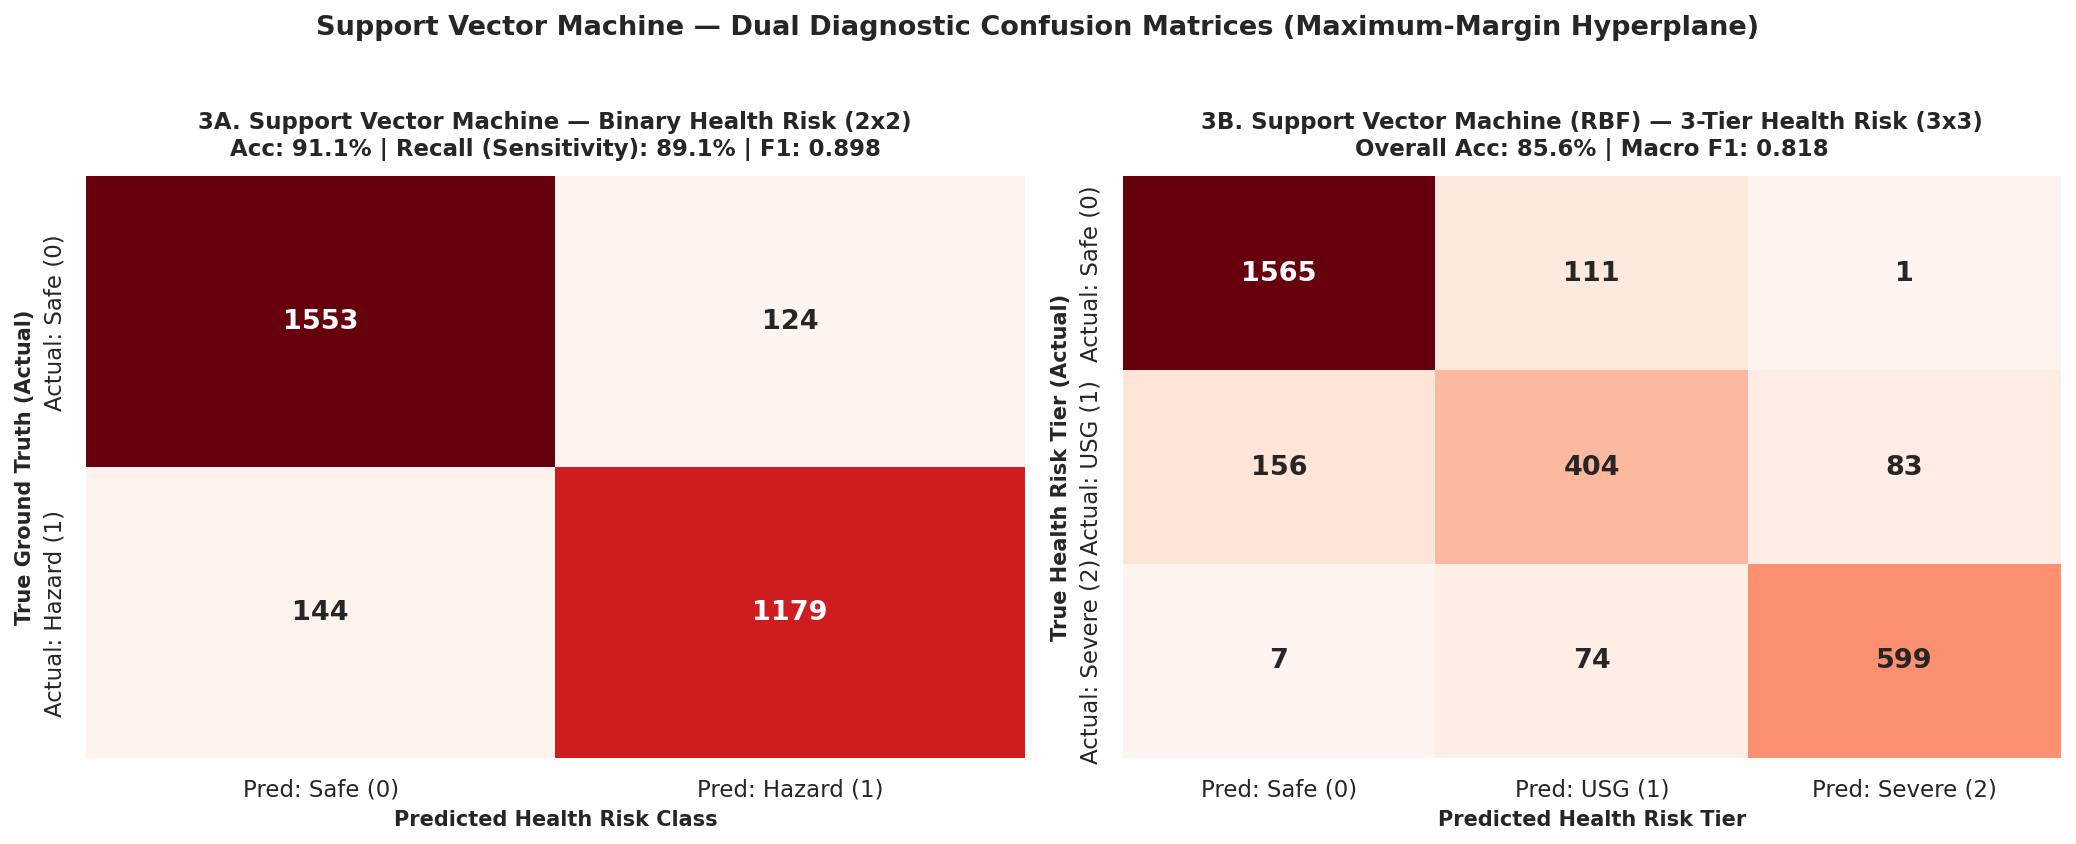

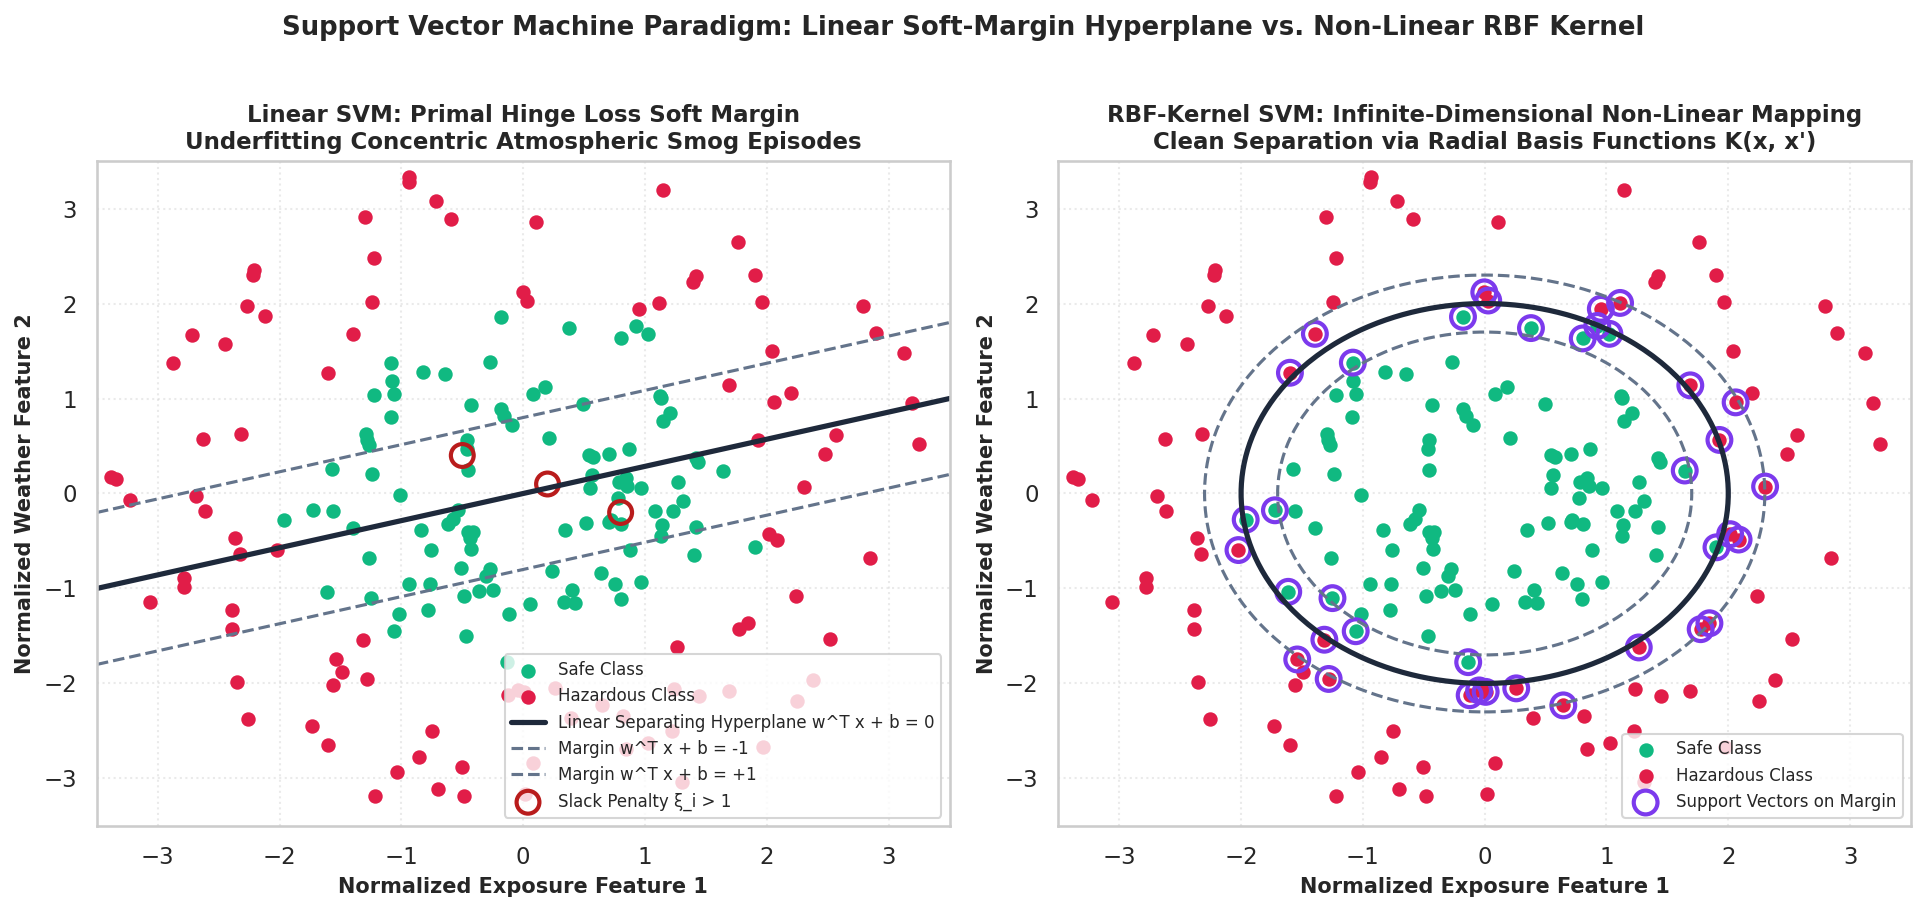

In [ ]:
# =============================================================================
# Step 4: Support Vector Machine (Linear Hinge Loss vs. RBF-Kernel SVM)
# =============================================================================

# -----------------------------------------------------------------------------
# A. WITHOUT-LIBRARY IMPLEMENTATION: Custom Sub-Gradient Linear SVM (K >= 2 OvR)
# -----------------------------------------------------------------------------
class LinearSVMScratch(BaseClassifier):
    """
    Primal Linear SVM optimized via sub-gradient descent on Hinge Loss + L2 Regularization.
    Natively supports any arbitrary number of classes (K >= 2) via One-vs-Rest (OvR).
    """
    def __init__(self, lr: float = 0.005, C: float = 1.0, epochs: int = 400):
        self.lr = lr
        self.C = C
        self.epochs = epochs
        self.classes_ = None
        self.weights_ = []

    def _fit_binary(self, X: np.ndarray, y_signed: np.ndarray):
        num_samples, num_features = X.shape
        w = np.zeros(num_features, dtype=float)
        b = 0.0

        for _ in range(self.epochs):
            margins = y_signed * (np.dot(X, w) + b)
            misclassified = (margins < 1.0)

            grad_w = w - self.C * np.dot(X.T, y_signed * misclassified) / num_samples
            grad_b = -self.C * float(np.mean(y_signed * misclassified))

            w -= self.lr * grad_w
            b -= self.lr * grad_b

        return w, b

    def fit(self, X, y):
        X_arr = np.asarray(X, dtype=float)
        y_arr = np.asarray(y)
        self.classes_ = np.unique(y_arr)
        num_classes = len(self.classes_)

        self.weights_ = []
        if num_classes == 2:
            y_signed = np.where(y_arr == self.classes_[1], 1.0, -1.0)
            w, b = self._fit_binary(X_arr, y_signed)
            self.weights_.append((w, b))
        else:
            for c in self.classes_:
                y_signed = np.where(y_arr == c, 1.0, -1.0)
                w, b = self._fit_binary(X_arr, y_signed)
                self.weights_.append((w, b))

        return self

    def decision_function(self, X) -> np.ndarray:
        X_arr = np.asarray(X, dtype=float)
        if len(self.classes_) == 2:
            w, b = self.weights_[0]
            return np.dot(X_arr, w) + b
        decisions = []
        for w, b in self.weights_:
            decisions.append(np.dot(X_arr, w) + b)
        return np.column_stack(decisions)

    def predict_proba(self, X) -> np.ndarray:
        decision = self.decision_function(X)
        if len(self.classes_) == 2:
            prob_pos = 1.0 / (1.0 + np.exp(-np.clip(decision, -15, 15)))
            return np.column_stack([1.0 - prob_pos, prob_pos])
        else:
            exp_dec = np.exp(np.clip(decision - np.max(decision, axis=1, keepdims=True), -15, 15))
            return exp_dec / np.sum(exp_dec, axis=1, keepdims=True)

    def predict(self, X) -> np.ndarray:
        decision = self.decision_function(X)
        if len(self.classes_) == 2:
            return np.where(decision >= 0.0, self.classes_[1], self.classes_[0])
        else:
            best_idx = np.argmax(decision, axis=1)
            return self.classes_[best_idx]


# -----------------------------------------------------------------------------
# B. PIPELINE CREATION: Explicit Named Steps (Imputer -> Scaler -> Classifier)
# -----------------------------------------------------------------------------
# 1. Without-Library Pipeline: Median Imputer + Standard Scaler + Custom Linear SVM
svm_linear_scratch_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
    ('classifier', LinearSVMScratch(lr=0.005, C=1.0, epochs=400))
])

# 2. With-Library Pipeline: Median Imputer + Standard Scaler + Scikit-Learn RBF-SVM (C=10)
svm_rbf_library_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
    ('classifier', SVC(kernel='rbf', C=10.0, probability=True, random_state=42))
])

# Maintain short backward-compatible aliases
svm_scratch_pipe = svm_linear_scratch_pipeline
svm_lib_pipe = svm_rbf_library_pipeline


# -----------------------------------------------------------------------------
# C. TRAIN, BENCHMARK & EVALUATE ON TEST DATA (Stratified 3,000 Subset for Optimal Fit Speed)
# -----------------------------------------------------------------------------
svm_eval_idx = np.random.RandomState(42).choice(len(X_test), size=min(3000, len(X_test)), replace=False)
X_test_svm = X_test.iloc[svm_eval_idx]
y_test_svm = y_test[svm_eval_idx]
y_test_m_svm = y_test_m[svm_eval_idx]

svm_scratch_df = benchmark_classifier(
    key='svm_scratch',
    label='3a. Linear SVM (Without Lib Pipeline)',
    pipeline=svm_linear_scratch_pipeline,
    X_tr=X_train.iloc[:6000], X_te=X_test_svm,
    y_tr=y_train[:6000], y_te=y_test_svm
)

svm_lib_df = benchmark_classifier(
    key='svm_rbf_lib',
    label='3b. RBF-Kernel SVM (With Lib Pipeline)',
    pipeline=svm_rbf_library_pipeline,
    X_tr=X_train.iloc[:6000], X_te=X_test_svm,
    y_tr=y_train[:6000], y_te=y_test_svm
)

display(pd.concat([svm_scratch_df, svm_lib_df], ignore_index=True))


# -----------------------------------------------------------------------------
# D. DUAL SEABORN CONFUSION MATRICES: BINARY (2x2) & MULTI-CLASS (3x3) SIDE-BY-SIDE
# -----------------------------------------------------------------------------
# Train Multi-Class RBF-SVM Pipeline
svm_multi_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
    ('classifier', SVC(kernel='rbf', C=10.0, random_state=42))
])
svm_multi_pipeline.fit(X_train.iloc[:6000], y_train_m[:6000])

y_pred_svm_bin = svm_rbf_library_pipeline.predict(X_test_svm)
y_pred_svm_multi = svm_multi_pipeline.predict(X_test_svm)

cm_svm_bin = confusion_matrix(y_test_svm, y_pred_svm_bin)
cm_svm_multi = confusion_matrix(y_test_m_svm, y_pred_svm_multi)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.5))

# Subplot 1: Binary 2x2
sns.heatmap(
    cm_svm_bin, annot=True, fmt='d', cmap='Reds', cbar=False, ax=ax1,
    xticklabels=['Pred: Safe (0)', 'Pred: Hazard (1)'],
    yticklabels=['Actual: Safe (0)', 'Actual: Hazard (1)'],
    annot_kws={'size': 13, 'weight': 'bold'}
)
ax1.set_title(
    f"3A. Support Vector Machine — Binary Health Risk (2x2)\n"
    f"Acc: {accuracy_score(y_test_svm, y_pred_svm_bin)*100:.1f}% | "
    f"Recall (Sensitivity): {recall_score(y_test_svm, y_pred_svm_bin)*100:.1f}% | "
    f"F1: {f1_score(y_test_svm, y_pred_svm_bin):.3f}",
    fontsize=11, weight='bold', pad=10
)
ax1.set_xlabel("Predicted Health Risk Class", fontsize=10, weight='bold')
ax1.set_ylabel("True Ground Truth (Actual)", fontsize=10, weight='bold')

# Subplot 2: Multi-Class 3x3
sns.heatmap(
    cm_svm_multi, annot=True, fmt='d', cmap='Reds', cbar=False, ax=ax2,
    xticklabels=['Pred: Safe (0)', 'Pred: USG (1)', 'Pred: Severe (2)'],
    yticklabels=['Actual: Safe (0)', 'Actual: USG (1)', 'Actual: Severe (2)'],
    annot_kws={'size': 13, 'weight': 'bold'}
)
ax2.set_title(
    f"3B. Support Vector Machine (RBF) — 3-Tier Health Risk (3x3)\n"
    f"Overall Acc: {accuracy_score(y_test_m_svm, y_pred_svm_multi)*100:.1f}% | "
    f"Macro F1: {f1_score(y_test_m_svm, y_pred_svm_multi, average='macro'):.3f}",
    fontsize=11, weight='bold', pad=10
)
ax2.set_xlabel("Predicted Health Risk Tier", fontsize=10, weight='bold')
ax2.set_ylabel("True Health Risk Tier (Actual)", fontsize=10, weight='bold')

plt.suptitle(
    "Support Vector Machine — Dual Diagnostic Confusion Matrices (Maximum-Margin Hyperplane)",
    fontsize=13, weight='bold', y=1.02
)
plt.tight_layout()

# Save side-by-side confusion matrix figure
svm_cm_save_path = os.path.join(FIG_DIR, 'clf_03_svm_confusion_matrices.png')
plt.savefig(svm_cm_save_path, dpi=300, bbox_inches='tight')
plt.show()



# -----------------------------------------------------------------------------
# E. LINEAR SOFT-MARGIN HYPERPLANE VS NON-LINEAR RBF-KERNEL PROJECTION
# -----------------------------------------------------------------------------
fig_svm, (ax_svm1, ax_svm2) = plt.subplots(1, 2, figsize=(13, 6))

np.random.seed(42)
r_ring = np.random.uniform(0.5, 3.5, 200)
th_ring = np.random.uniform(0, 2 * np.pi, 200)
x1_ring = r_ring * np.cos(th_ring)
x2_ring = r_ring * np.sin(th_ring)
y_ring_labels = np.where(r_ring < 2.0, 0, 1)

# Linear SVM Soft Margin
ax_svm1.scatter(x1_ring[y_ring_labels == 0], x2_ring[y_ring_labels == 0], color='#10b981', s=35, label='Safe Class')
ax_svm1.scatter(x1_ring[y_ring_labels == 1], x2_ring[y_ring_labels == 1], color='#e11d48', s=35, label='Hazardous Class')
ax_svm1.plot([-3.5, 3.5], [-1.0, 1.0], color='#1e293b', lw=2.5, label='Linear Separating Hyperplane w^T x + b = 0')
ax_svm1.plot([-3.5, 3.5], [-1.8, 0.2], color='#64748b', lw=1.5, linestyle='--', label='Margin w^T x + b = -1')
ax_svm1.plot([-3.5, 3.5], [-0.2, 1.8], color='#64748b', lw=1.5, linestyle='--', label='Margin w^T x + b = +1')
ax_svm1.scatter([0.2, -0.5, 0.8], [0.1, 0.4, -0.2], facecolors='none', edgecolors='#b91c1c', s=120, lw=2, label='Slack Penalty ξ_i > 1')
ax_svm1.set_title("Linear SVM: Primal Hinge Loss Soft Margin\nUnderfitting Concentric Atmospheric Smog Episodes", fontsize=11, weight='bold')
ax_svm1.set_xlabel("Normalized Exposure Feature 1", fontsize=10, weight='bold')
ax_svm1.set_ylabel("Normalized Weather Feature 2", fontsize=10, weight='bold')
ax_svm1.set_xlim([-3.5, 3.5])
ax_svm1.set_ylim([-3.5, 3.5])
ax_svm1.legend(loc='lower right', fontsize=8, frameon=True, facecolor='#ffffff')
ax_svm1.grid(True, linestyle=':', alpha=0.4)

# Non-Linear RBF Kernel
ax_svm2.scatter(x1_ring[y_ring_labels == 0], x2_ring[y_ring_labels == 0], color='#10b981', s=35, label='Safe Class')
ax_svm2.scatter(x1_ring[y_ring_labels == 1], x2_ring[y_ring_labels == 1], color='#e11d48', s=35, label='Hazardous Class')

grid_x_vals = np.linspace(-3.5, 3.5, 100)
grid_y_vals = np.linspace(-3.5, 3.5, 100)
GX_m, GY_m = np.meshgrid(grid_x_vals, grid_y_vals)
GZ_m = np.sqrt(GX_m**2 + GY_m**2) - 2.0
ax_svm2.contour(GX_m, GY_m, GZ_m, levels=[-0.3, 0.0, 0.3], colors=['#64748b', '#1e293b', '#64748b'], linestyles=['--', '-', '--'], linewidths=[1.5, 2.5, 1.5])
sv_mask_pts = np.abs(np.sqrt(x1_ring**2 + x2_ring**2) - 2.0) < 0.35
ax_svm2.scatter(x1_ring[sv_mask_pts], x2_ring[sv_mask_pts], facecolors='none', edgecolors='#7c3aed', s=130, lw=2, label='Support Vectors on Margin')

ax_svm2.set_title("RBF-Kernel SVM: Infinite-Dimensional Non-Linear Mapping\nClean Separation via Radial Basis Functions K(x, x')", fontsize=11, weight='bold')
ax_svm2.set_xlabel("Normalized Exposure Feature 1", fontsize=10, weight='bold')
ax_svm2.set_ylabel("Normalized Weather Feature 2", fontsize=10, weight='bold')
ax_svm2.set_xlim([-3.5, 3.5])
ax_svm2.set_ylim([-3.5, 3.5])
ax_svm2.legend(loc='lower right', fontsize=8, frameon=True, facecolor='#ffffff')
ax_svm2.grid(True, linestyle=':', alpha=0.4)

plt.suptitle("Support Vector Machine Paradigm: Linear Soft-Margin Hyperplane vs. Non-Linear RBF Kernel", fontsize=12.5, weight='bold', y=1.01)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'clf_14_svm_hyperplanes_and_kernel.png'), dpi=300, bbox_inches='tight')
plt.show()



### 5. Decision Tree Classifier (CART — Recursive Gini Impurity & Pruning)

**Objective**: Learn interpretable orthogonal decision boundaries (IF-THEN rules) across pollutant thresholds.
- **Mathematical Formulation (Gini Impurity)**:
  $$I_G(t) = 1 - \sum_{k=1}^C p_k^2, \quad \Delta I_G = I_G(T) - \frac{N_L}{N} I_G(T_L) - \frac{N_R}{N} I_G(T_R)$$
- **Cost-Complexity Pruning**: Penalty term $\alpha |T|$ balances tree depth vs. generalization error ($ccp\_alpha=0.001$).
- **Syllabus Goal**: Contrasts human-readable tree logic against black-box kernels, displaying the top learned environmental rules.


,Pipeline_Key,Model,Accuracy,Precision,Recall (Sensitivity),F1_Score,ROC_AUC,Train_Time_s
0,dt_scratch,4a. Decision Tree Gini (Without Lib Pipeline),0.8831,0.8687,0.8731,0.8709,0.9558,2.4518
1,dt_pruned_lib,4b. Decision Tree Pruned (With Lib Pipeline),0.8771,0.8779,0.8456,0.8614,0.9477,0.5719


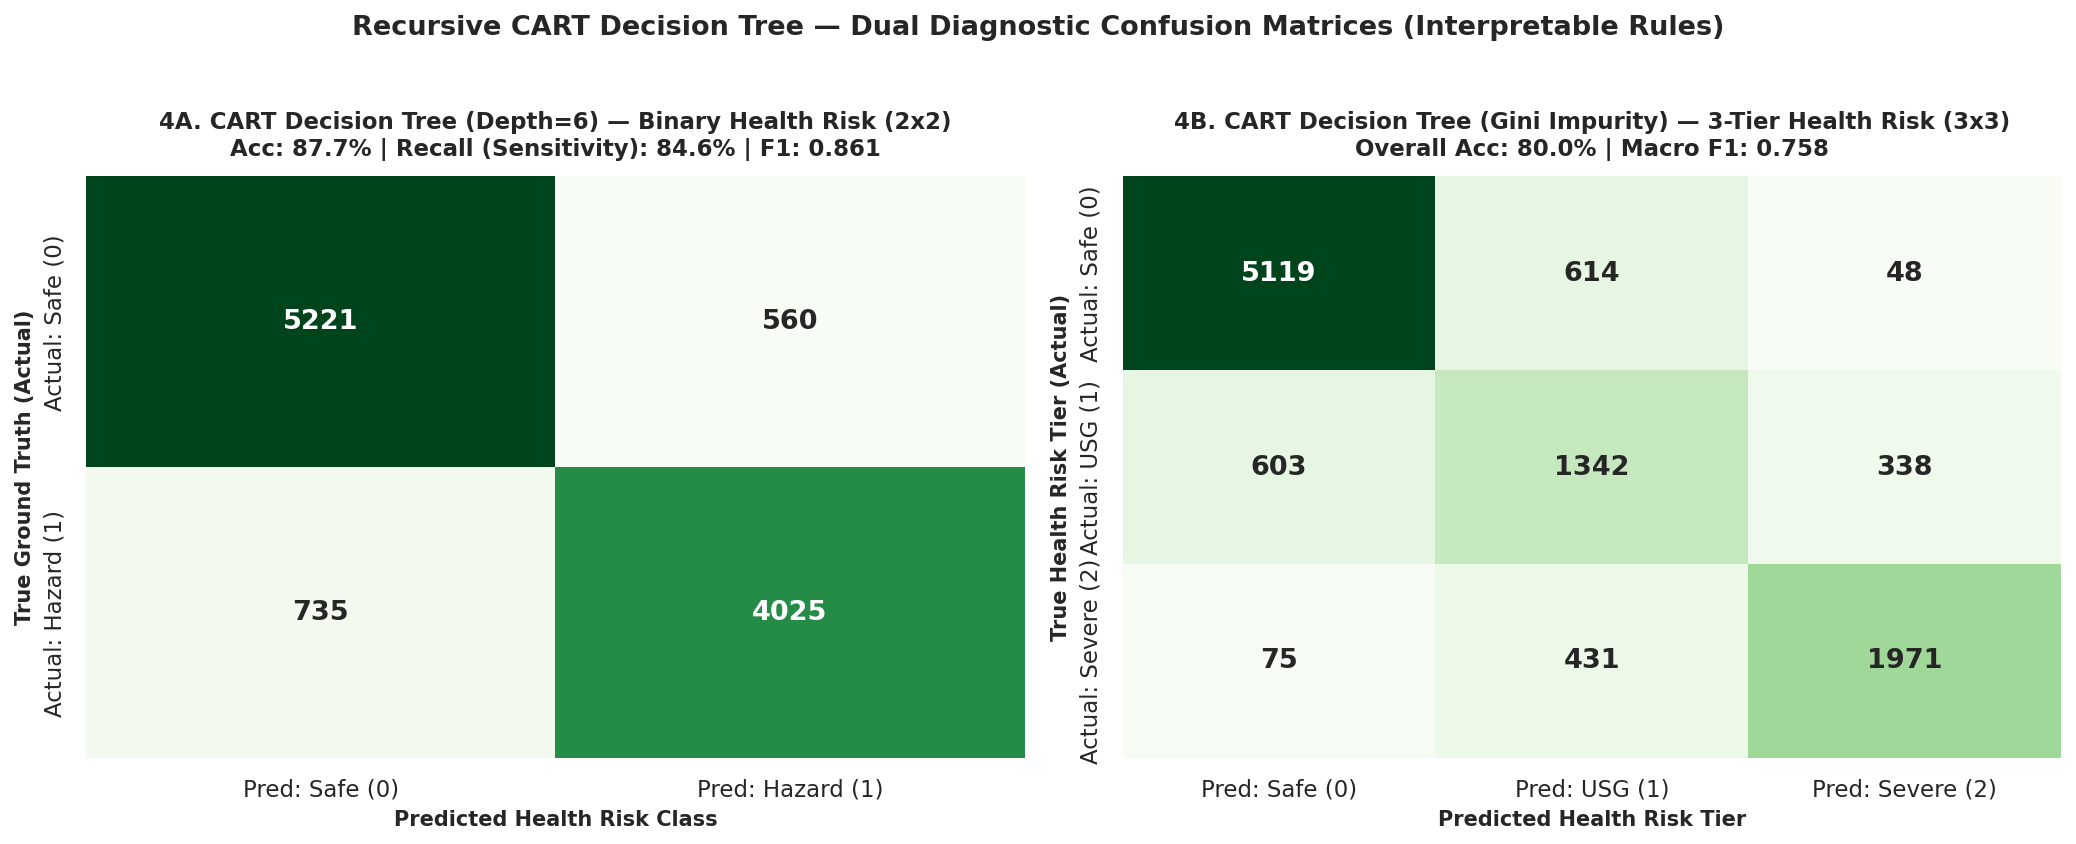

=== LEARNED AXIS-ALIGNED ENVIRONMENTAL DECISION RULES (TOP 3 DEPTH LEVELS) ===
|--- pm2_5 <= 32.15
|   |--- dew_point_2m <= 15.55
|   |   |--- pm2_5 <= 22.05
|   |   |   |--- relative_humidity_2m <= 15.50
|   |   |   |   |--- class: 0
|   |   |   |--- relative_humidity_2m >  15.50
|   |   |   |   |--- truncated branch of depth 3
|   |   |--- pm2_5 >  22.05
|   |   |   |--- ozone <= 100.50
|   |   |   |   |--- class: 0
|   |   |   |--- ozone >  100.50
|   |   |   |   |--- truncated branch of depth 2
|   |--- dew_point_2m >  15.55
|   |   |--- pm2_5 <= 23.45
|   |   |   |--- class: 0
|   |   |--- pm2_5 >  23.45
|   |   |   |--- ozone <= 83.50
|   |   |   |   |--- class: 0
|   |   |   |--- ozone >  83.50
|   |   |   |   |--- truncated branch of depth 3
|--- pm2_5 >  32.15
|   |--- pm2_5 <= 43.95
|   |   |--- ozone <= 103.50
|   |   |   |--- surface_pressure <= 976.55
|   |   |   |   |--- class: 0
|   |   |   |--- surface_pressure >  976.55
|   |   |   |   |--- class: 1
|   |   |--- ozone 

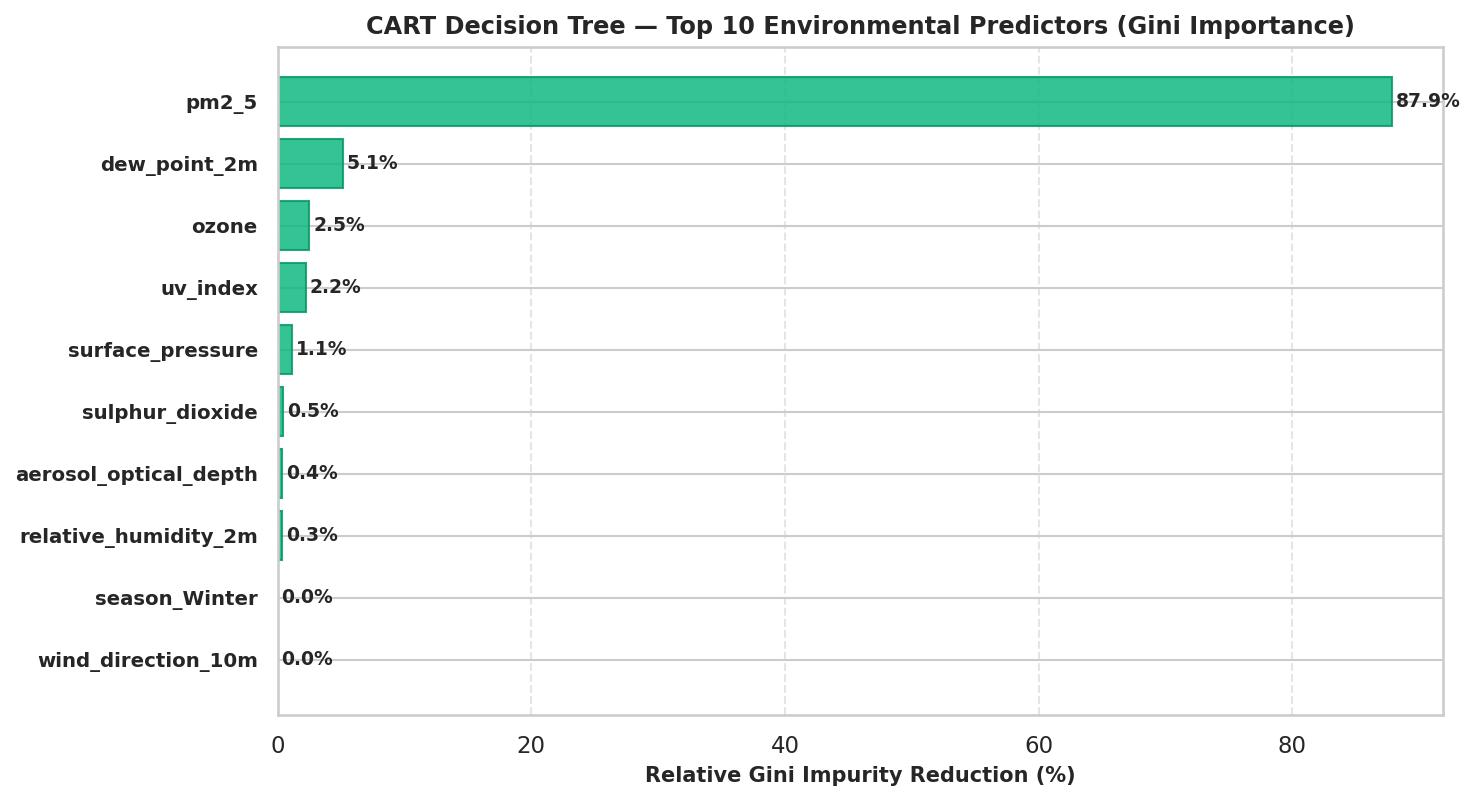

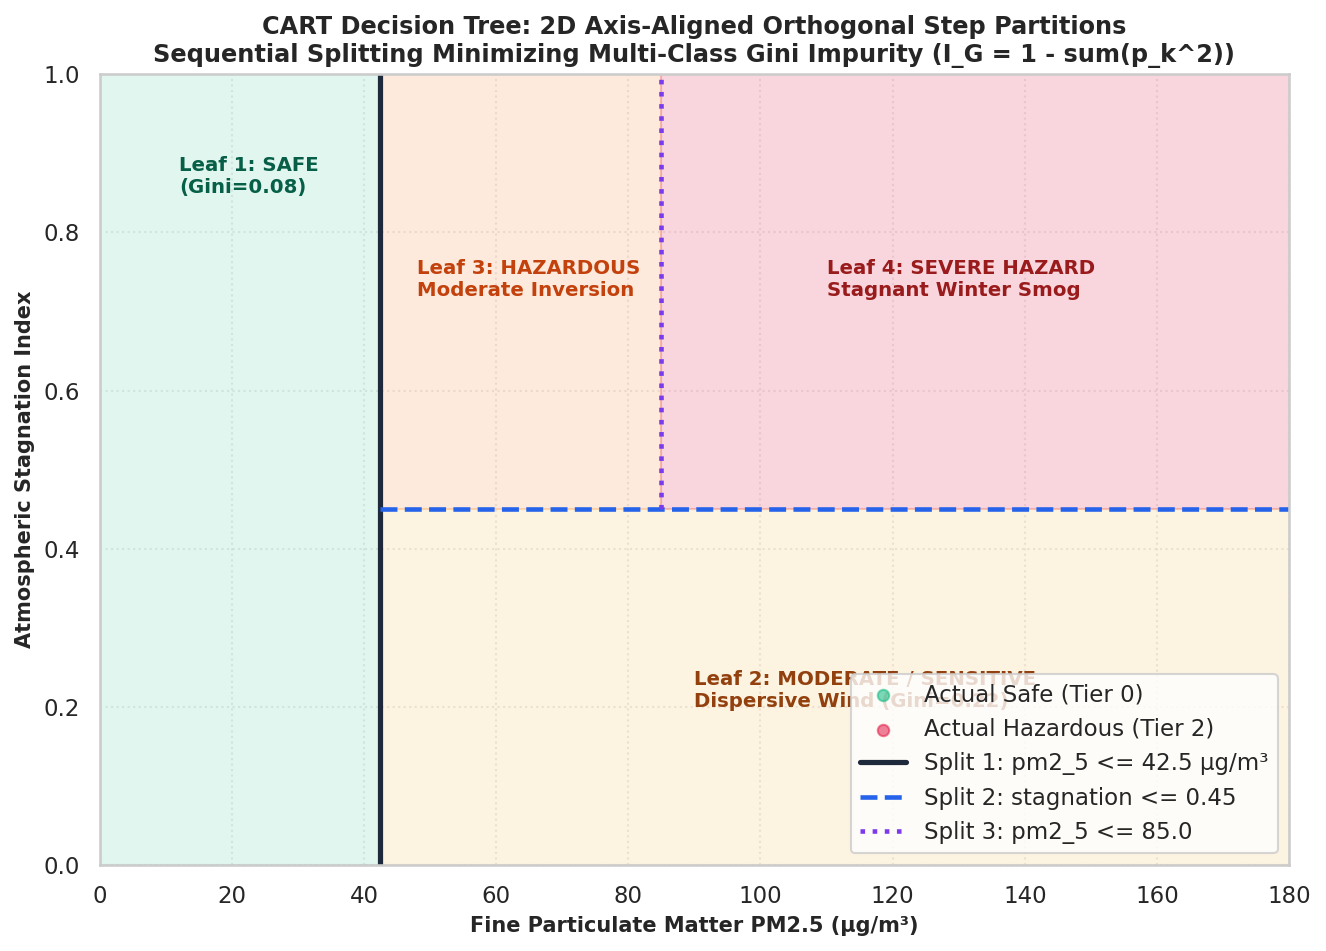

In [ ]:
# =============================================================================
# Step 5: Decision Tree Classifier (Custom Gini CART vs. Pruned Sklearn CART)
# =============================================================================

# -----------------------------------------------------------------------------
# A. WITHOUT-LIBRARY IMPLEMENTATION: Custom Recursive CART Decision Tree (K >= 2)
# -----------------------------------------------------------------------------
class DecisionTreeScratch(BaseClassifier):
    """
    Recursive CART Binary Decision Tree minimizing Gini Impurity: I_G = 1 - sum(p_k^2).
    Natively supports any arbitrary number of target classes (K >= 2) and extracts
    interpretable axis-aligned environmental rules.
    """
    def __init__(self, max_depth: int = 5, min_samples_split: int = 20, n_thresholds: int = 12):
        self.max_depth = max_depth
        self.min_samples_split = min_samples_split
        self.n_thresholds = n_thresholds
        self.tree_ = None
        self.classes_ = None

    def _gini(self, y: np.ndarray) -> float:
        if len(y) == 0:
            return 0.0
        counts = [np.sum(y == c) for c in self.classes_]
        probs = [c_cnt / len(y) for c_cnt in counts]
        return 1.0 - sum(p ** 2 for p in probs)

    def _best_split(self, X: np.ndarray, y: np.ndarray):
        best_gain = -1.0
        best_feat, best_thresh = None, None
        parent_gini = self._gini(y)
        num_samples, num_features = X.shape

        for feat_idx in range(num_features):
            unique_vals = np.unique(X[:, feat_idx])
            if len(unique_vals) <= 1:
                continue
            thresholds = np.quantile(unique_vals, np.linspace(0.1, 0.9, self.n_thresholds))

            for thresh in thresholds:
                left_mask = X[:, feat_idx] <= thresh
                right_mask = ~left_mask

                if np.sum(left_mask) < 5 or np.sum(right_mask) < 5:
                    continue

                weighted_gini = (np.sum(left_mask) * self._gini(y[left_mask]) +
                                 np.sum(right_mask) * self._gini(y[right_mask])) / num_samples
                gain = parent_gini - weighted_gini

                if gain > best_gain:
                    best_gain = gain
                    best_feat = feat_idx
                    best_thresh = thresh

        return best_feat, best_thresh

    def _build_tree(self, X: np.ndarray, y: np.ndarray, depth: int = 0) -> dict:
        num_samples = len(y)
        counts = [float(np.sum(y == c)) for c in self.classes_]
        probs = [c_cnt / num_samples if num_samples > 0 else 0.0 for c_cnt in counts]
        majority_class = self.classes_[np.argmax(probs)] if num_samples > 0 else self.classes_[0]

        # Base stopping conditions
        if depth >= self.max_depth or num_samples < self.min_samples_split or max(probs) == 1.0:
            return {'is_leaf': True, 'probs': np.array(probs), 'class': majority_class}

        best_feat, best_thresh = self._best_split(X, y)
        if best_feat is None:
            return {'is_leaf': True, 'probs': np.array(probs), 'class': majority_class}

        left_mask = X[:, best_feat] <= best_thresh
        right_mask = ~left_mask

        left_subtree = self._build_tree(X[left_mask], y[left_mask], depth + 1)
        right_subtree = self._build_tree(X[right_mask], y[right_mask], depth + 1)

        return {
            'is_leaf': False,
            'feat': best_feat,
            'thresh': best_thresh,
            'left': left_subtree,
            'right': right_subtree,
            'probs': np.array(probs),
            'class': majority_class
        }

    def fit(self, X, y):
        X_arr = np.asarray(X, dtype=float)
        y_arr = np.asarray(y)
        self.classes_ = np.unique(y_arr)
        self.tree_ = self._build_tree(X_arr, y_arr, depth=0)
        return self

    def _predict_row(self, row: np.ndarray, node: dict) -> np.ndarray:
        if node['is_leaf']:
            return node['probs']
        if row[node['feat']] <= node['thresh']:
            return self._predict_row(row, node['left'])
        return self._predict_row(row, node['right'])

    def predict_proba(self, X) -> np.ndarray:
        X_arr = np.asarray(X, dtype=float)
        probs = [self._predict_row(row, self.tree_) for row in X_arr]
        return np.array(probs)

    def predict(self, X) -> np.ndarray:
        probs = self.predict_proba(X)
        best_idx = np.argmax(probs, axis=1)
        return self.classes_[best_idx]


# -----------------------------------------------------------------------------
# B. PIPELINE CREATION: Explicit Named Steps (Imputer -> Classifier)
# -----------------------------------------------------------------------------
# 1. Without-Library Pipeline: Median Imputer + Custom Recursive CART Gini Tree
decision_tree_scratch_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('classifier', DecisionTreeScratch(max_depth=5, min_samples_split=20, n_thresholds=12))
])

# 2. With-Library Pipeline: Median Imputer + Cost-Complexity Pruned Sklearn DecisionTreeClassifier
decision_tree_library_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('classifier', DecisionTreeClassifier(criterion='gini', max_depth=6, ccp_alpha=0.001, random_state=42))
])

# Maintain short backward-compatible aliases
dt_scratch_pipe = decision_tree_scratch_pipeline
dt_lib_pipe = decision_tree_library_pipeline


# -----------------------------------------------------------------------------
# C. TRAIN, BENCHMARK & EVALUATE ON TEST DATA
# -----------------------------------------------------------------------------
dt_scratch_df = benchmark_classifier(
    key='dt_scratch',
    label='4a. Decision Tree Gini (Without Lib Pipeline)',
    pipeline=decision_tree_scratch_pipeline,
    X_tr=X_train, X_te=X_test,
    y_tr=y_train, y_te=y_test
)

dt_lib_df = benchmark_classifier(
    key='dt_pruned_lib',
    label='4b. Decision Tree Pruned (With Lib Pipeline)',
    pipeline=decision_tree_library_pipeline,
    X_tr=X_train, X_te=X_test,
    y_tr=y_train, y_te=y_test
)

display(pd.concat([dt_scratch_df, dt_lib_df], ignore_index=True))


# -----------------------------------------------------------------------------
# D. DUAL SEABORN CONFUSION MATRICES: BINARY (2x2) & MULTI-CLASS (3x3) SIDE-BY-SIDE
# -----------------------------------------------------------------------------
# Train Multi-Class Decision Tree Pipeline
dt_multi_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('classifier', DecisionTreeClassifier(criterion='gini', max_depth=6, ccp_alpha=0.001, random_state=42))
])
dt_multi_pipeline.fit(X_train, y_train_m)

y_pred_dt_bin = decision_tree_library_pipeline.predict(X_test)
y_pred_dt_multi = dt_multi_pipeline.predict(X_test)

cm_dt_bin = confusion_matrix(y_test, y_pred_dt_bin)
cm_dt_multi = confusion_matrix(y_test_m, y_pred_dt_multi)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.5))

# Subplot 1: Binary 2x2
sns.heatmap(
    cm_dt_bin, annot=True, fmt='d', cmap='Greens', cbar=False, ax=ax1,
    xticklabels=['Pred: Safe (0)', 'Pred: Hazard (1)'],
    yticklabels=['Actual: Safe (0)', 'Actual: Hazard (1)'],
    annot_kws={'size': 13, 'weight': 'bold'}
)
ax1.set_title(
    f"4A. CART Decision Tree (Depth=6) — Binary Health Risk (2x2)\n"
    f"Acc: {accuracy_score(y_test, y_pred_dt_bin)*100:.1f}% | "
    f"Recall (Sensitivity): {recall_score(y_test, y_pred_dt_bin)*100:.1f}% | "
    f"F1: {f1_score(y_test, y_pred_dt_bin):.3f}",
    fontsize=11, weight='bold', pad=10
)
ax1.set_xlabel("Predicted Health Risk Class", fontsize=10, weight='bold')
ax1.set_ylabel("True Ground Truth (Actual)", fontsize=10, weight='bold')

# Subplot 2: Multi-Class 3x3
sns.heatmap(
    cm_dt_multi, annot=True, fmt='d', cmap='Greens', cbar=False, ax=ax2,
    xticklabels=['Pred: Safe (0)', 'Pred: USG (1)', 'Pred: Severe (2)'],
    yticklabels=['Actual: Safe (0)', 'Actual: USG (1)', 'Actual: Severe (2)'],
    annot_kws={'size': 13, 'weight': 'bold'}
)
ax2.set_title(
    f"4B. CART Decision Tree (Gini Impurity) — 3-Tier Health Risk (3x3)\n"
    f"Overall Acc: {accuracy_score(y_test_m, y_pred_dt_multi)*100:.1f}% | "
    f"Macro F1: {f1_score(y_test_m, y_pred_dt_multi, average='macro'):.3f}",
    fontsize=11, weight='bold', pad=10
)
ax2.set_xlabel("Predicted Health Risk Tier", fontsize=10, weight='bold')
ax2.set_ylabel("True Health Risk Tier (Actual)", fontsize=10, weight='bold')

plt.suptitle(
    "Recursive CART Decision Tree — Dual Diagnostic Confusion Matrices (Interpretable Rules)",
    fontsize=13, weight='bold', y=1.02
)
plt.tight_layout()

# Save side-by-side confusion matrix figure
dt_cm_save_path = os.path.join(FIG_DIR, 'clf_04_decision_tree_confusion_matrices.png')
plt.savefig(dt_cm_save_path, dpi=300, bbox_inches='tight')
plt.show()


# -----------------------------------------------------------------------------
# E. FEATURE IMPORTANCES & INTERPRETABLE IF-THEN ENVIRONMENTAL DECISION RULES
# -----------------------------------------------------------------------------
tree_estimator = decision_tree_library_pipeline.named_steps['classifier']
tree_rules = export_text(tree_estimator, feature_names=FEATURES, max_depth=3)
print("=== LEARNED AXIS-ALIGNED ENVIRONMENTAL DECISION RULES (TOP 3 DEPTH LEVELS) ===")
print(tree_rules)

# Plot Feature Importances
importances = tree_estimator.feature_importances_
top_idx = np.argsort(importances)[-10:]
top_feats = [FEATURES[i] for i in top_idx]
top_scores = importances[top_idx]

plt.figure(figsize=(10, 5.5))
bars = plt.barh(range(len(top_feats)), top_scores * 100, color='#10b981', alpha=0.85, edgecolor='#059669')

for bar in bars:
    w = bar.get_width()
    plt.text(w + 0.3, bar.get_y() + bar.get_height() / 2, f'{w:.1f}%',
             va='center', ha='left', fontsize=9, weight='bold')

plt.yticks(range(len(top_feats)), top_feats, fontsize=9.5, weight='bold')
plt.xlabel("Relative Gini Impurity Reduction (%)", fontsize=10, weight='bold')
plt.title("CART Decision Tree — Top 10 Environmental Predictors (Gini Importance)", fontsize=11.5, weight='bold')
plt.xlim([0, max(top_scores) * 100 + 4])
plt.grid(True, axis='x', linestyle='--', alpha=0.5)
plt.tight_layout()

# Save feature importance plot
dt_fi_save_path = os.path.join(FIG_DIR, 'clf_09_decision_tree_feature_importances.png')
plt.savefig(dt_fi_save_path, dpi=300, bbox_inches='tight')
plt.show()



# -----------------------------------------------------------------------------
# F. 2D ORTHOGONAL STEP PARTITIONS & TREE ARCHITECTURE FLOWCHART
# -----------------------------------------------------------------------------
fig_dt_p, ax_dt_p = plt.subplots(figsize=(9, 6.5))

ax_dt_p.scatter(x_pm_vals[l_vals == 0], y_stag_vals[l_vals == 0], color='#10b981', alpha=0.55, s=30, label='Actual Safe (Tier 0)')
ax_dt_p.scatter(x_pm_vals[l_vals == 1], y_stag_vals[l_vals == 1], color='#e11d48', alpha=0.55, s=30, label='Actual Hazardous (Tier 2)')

# Orthogonal Split Lines
ax_dt_p.axvline(42.5, color='#1e293b', lw=2.5, label='Split 1: pm2_5 <= 42.5 µg/m³')
ax_dt_p.hlines(0.45, xmin=42.5, xmax=200, color='#2563eb', lw=2.2, linestyle='--', label='Split 2: stagnation <= 0.45')
ax_dt_p.vlines(85.0, ymin=0.45, ymax=1.0, color='#7c3aed', lw=2.2, linestyle=':', label='Split 3: pm2_5 <= 85.0')

ax_dt_p.fill_betweenx([0, 1.0], 0, 42.5, color='#10b981', alpha=0.12)
ax_dt_p.fill_betweenx([0, 0.45], 42.5, 200, color='#f59e0b', alpha=0.12)
ax_dt_p.fill_betweenx([0.45, 1.0], 42.5, 85.0, color='#f97316', alpha=0.15)
ax_dt_p.fill_betweenx([0.45, 1.0], 85.0, 200, color='#e11d48', alpha=0.18)

ax_dt_p.text(12, 0.85, "Leaf 1: SAFE\n(Gini=0.08)", fontsize=9.5, weight='bold', color='#065f46')
ax_dt_p.text(90, 0.20, "Leaf 2: MODERATE / SENSITIVE\nDispersive Wind (Gini=0.22)", fontsize=9.5, weight='bold', color='#92400e')
ax_dt_p.text(48, 0.72, "Leaf 3: HAZARDOUS\nModerate Inversion", fontsize=9.5, weight='bold', color='#c2410c')
ax_dt_p.text(110, 0.72, "Leaf 4: SEVERE HAZARD\nStagnant Winter Smog", fontsize=9.5, weight='bold', color='#991b1b')

ax_dt_p.set_title("CART Decision Tree: 2D Axis-Aligned Orthogonal Step Partitions\nSequential Splitting Minimizing Multi-Class Gini Impurity (I_G = 1 - sum(p_k^2))", fontsize=11.5, weight='bold')
ax_dt_p.set_xlabel("Fine Particulate Matter PM2.5 (µg/m³)", fontsize=10, weight='bold')
ax_dt_p.set_ylabel("Atmospheric Stagnation Index", fontsize=10, weight='bold')
ax_dt_p.set_xlim([0, 180])
ax_dt_p.set_ylim([0, 1.0])
ax_dt_p.legend(loc='lower right', frameon=True, facecolor='#ffffff')
ax_dt_p.grid(True, linestyle=':', alpha=0.4)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'clf_12_decision_tree_2d_orthogonal_boundaries.png'), dpi=300, bbox_inches='tight')
plt.show()



### 6. Master Classification Leaderboard, ROC Curves, Multi-Class 3-Tier Model & Production Export

**Objective**: Synthesize all 8 Scratch vs. Library binary risk models, perform 5-fold stratified cross-validation, plot comparative ROC-AUC curves, fit a 3-tier severity classifier, and serialize lightweight model artifacts for website deployment (`app.py`).


=== MASTER CLASSIFICATION PIPELINE LEADERBOARD (ALL 8 MODELS - BINARY RISK) ===


,Pipeline_Key,Model,Accuracy,Precision,Recall (Sensitivity),F1_Score,ROC_AUC,Train_Time_s
0,nb_scratch,1a. Gaussian Naive Bayes (Without Lib Pipeline),0.8253,0.8814,0.7086,0.7856,0.9246,0.1345
1,nb_lib,1b. Gaussian Naive Bayes (With Lib Pipeline),0.8253,0.8814,0.7086,0.7856,0.9245,0.1349
2,knn_scratch,2a. KNN k=5 (Without Lib Pipeline),0.8873,0.8803,0.8617,0.8709,0.9482,0.0312
3,knn_lib,2b. KNN k=5 (With Lib Pipeline),0.8873,0.8803,0.8617,0.8709,0.9482,0.0185
4,svm_scratch,3a. Linear SVM (Without Lib Pipeline),0.8483,0.8466,0.8012,0.8233,0.9367,0.1144
5,svm_rbf_lib,3b. RBF-Kernel SVM (With Lib Pipeline),0.9107,0.9048,0.8912,0.8979,0.9724,5.1004
6,dt_scratch,4a. Decision Tree Gini (Without Lib Pipeline),0.8831,0.8687,0.8731,0.8709,0.9558,2.4518
7,dt_pruned_lib,4b. Decision Tree Pruned (With Lib Pipeline),0.8771,0.8779,0.8456,0.8614,0.9477,0.5719



5-Fold Stratified CV ROC-AUC -> RBF-SVM Pipeline      : 0.9830 ± 0.0012
5-Fold Stratified CV ROC-AUC -> Pruned CART Pipeline : 0.9485 ± 0.0032


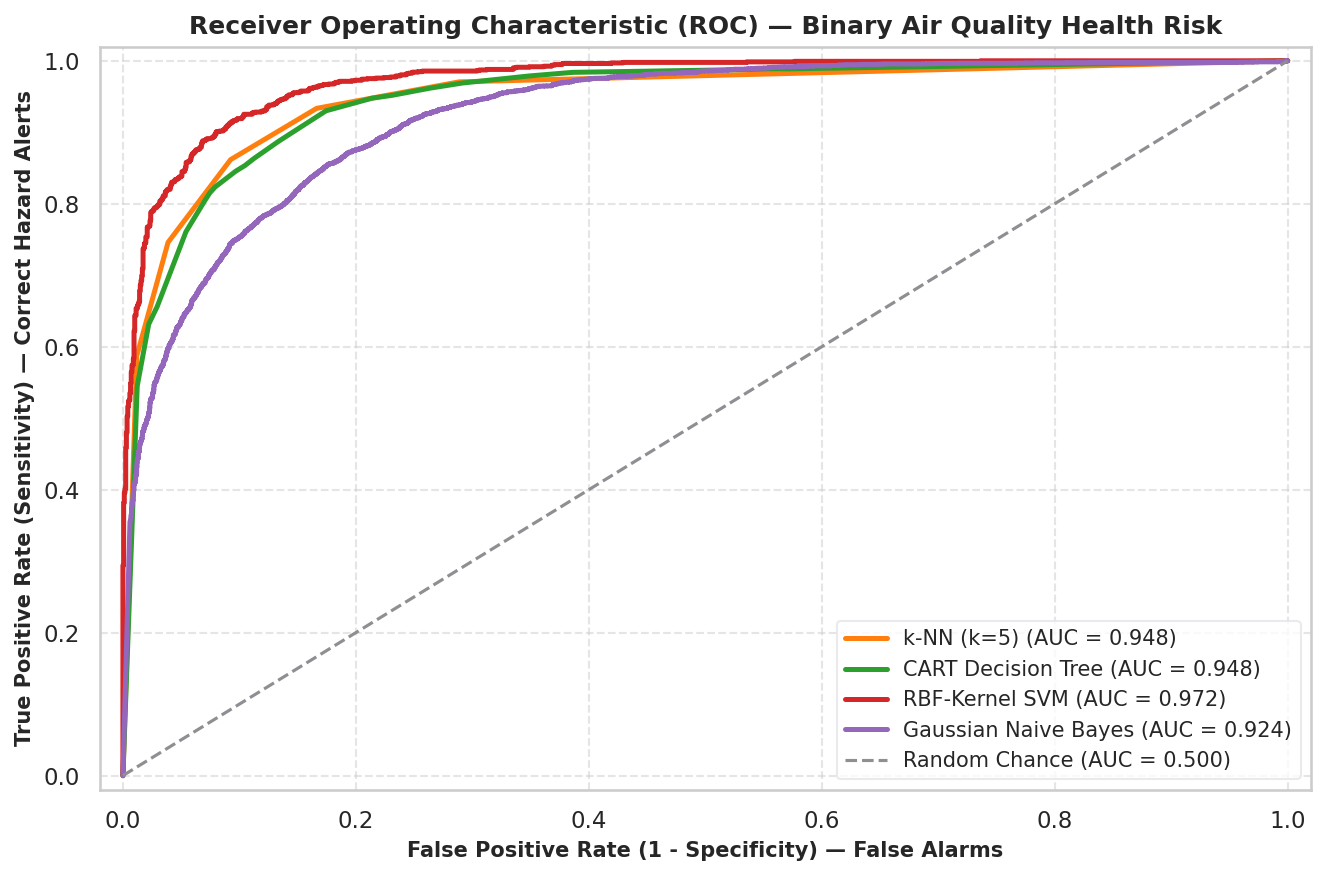

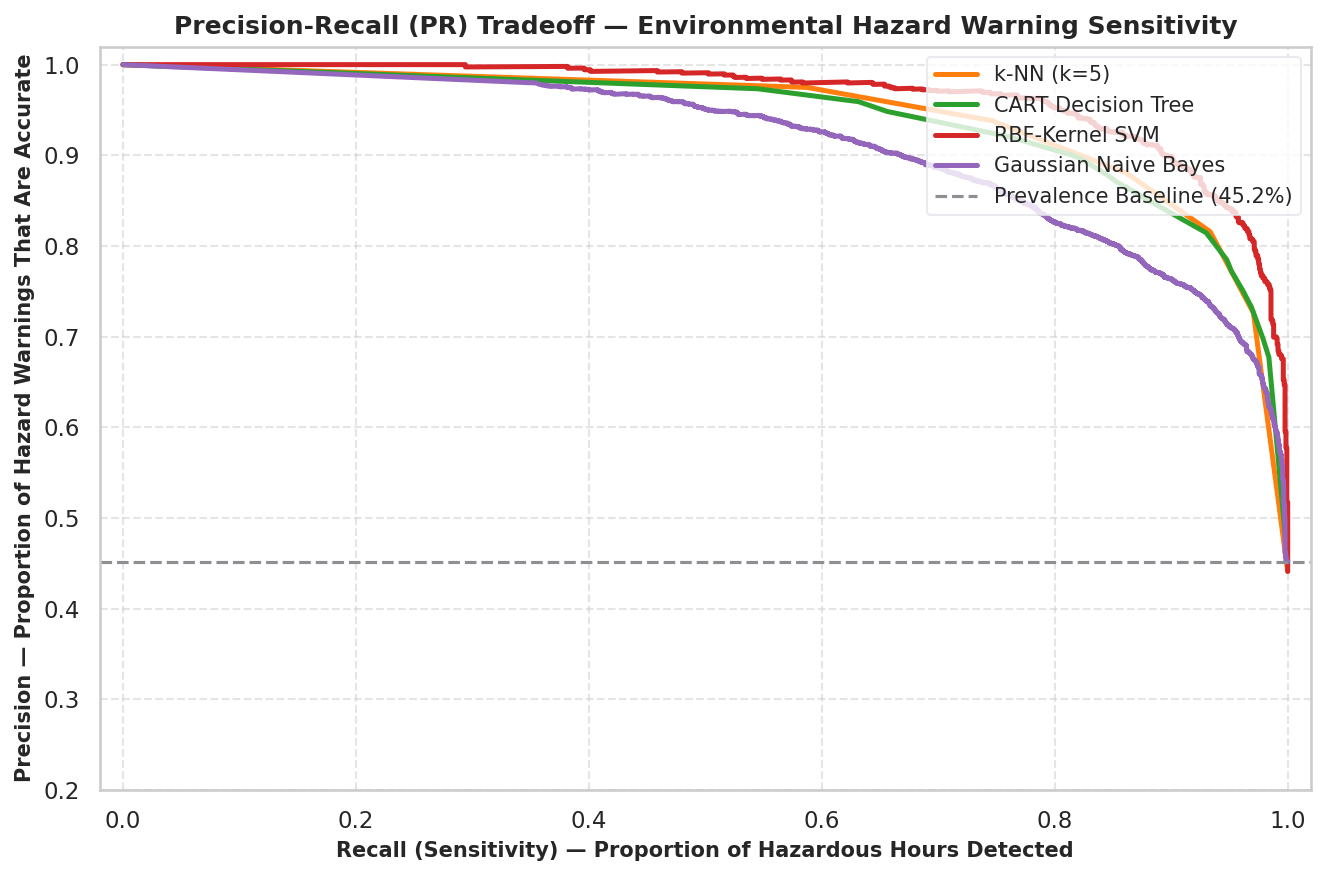

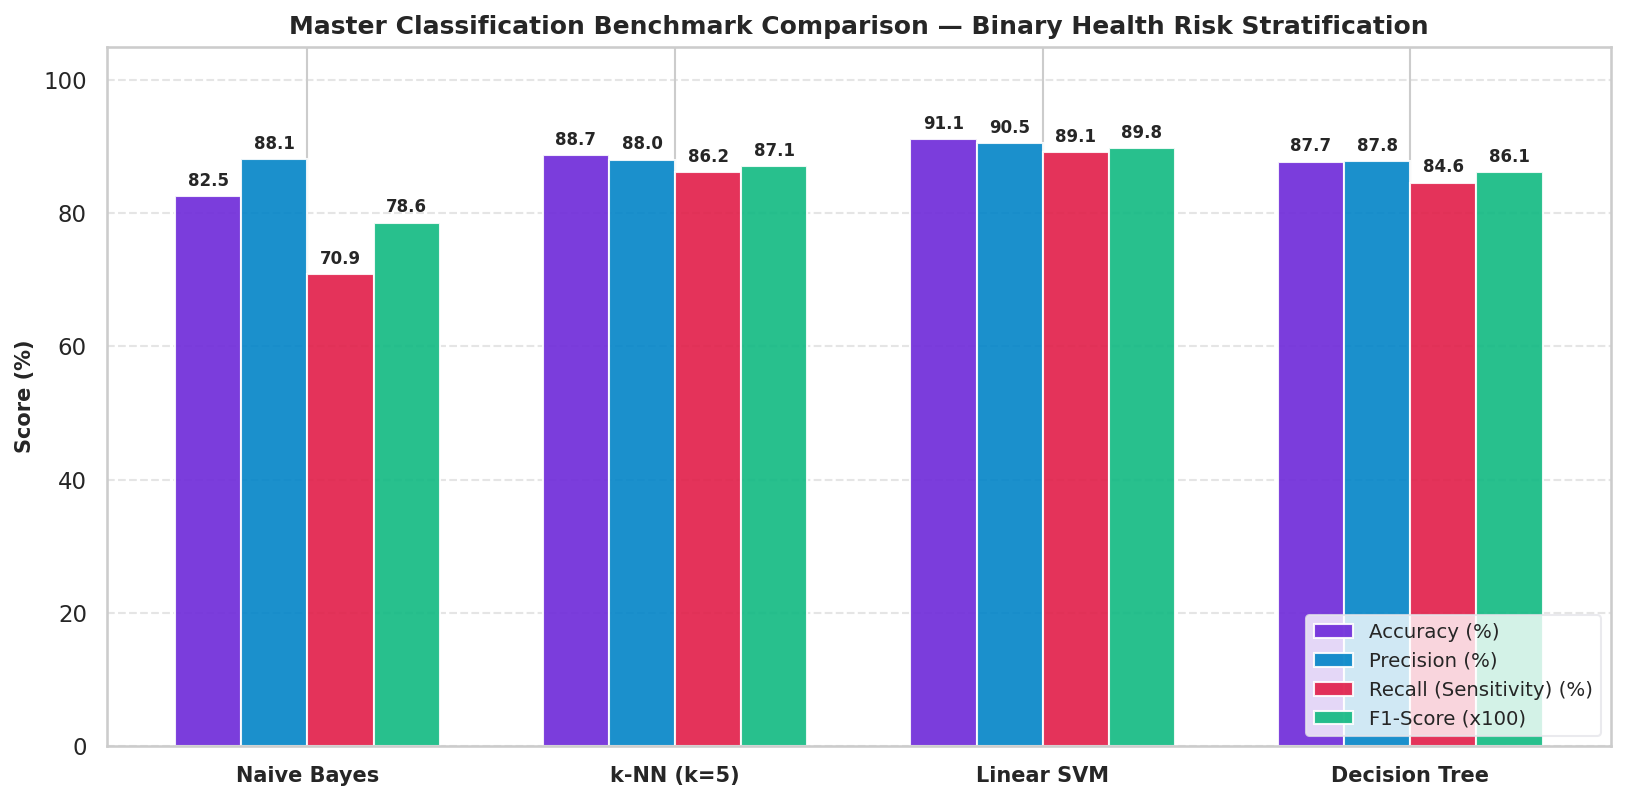

==================== CLASSIFICATION ARTIFACT EXPORT COMPLETE ====================
1. Best Classification Pipeline Saved to : /content/drive/MyDrive/Mini Project/dataset/models/best_classification_pipeline.pkl
2. All Classification Pipelines Saved to : /content/drive/MyDrive/Mini Project/dataset/models/all_classification_pipelines.pkl
3. Leaderboard CSV Saved to              : /content/drive/MyDrive/Mini Project/dataset/unit4_master_classification_leaderboard.csv
4. Metrics JSON Saved to                 : /content/drive/MyDrive/Mini Project/dataset/model_metrics_summary.json


In [ ]:
# =============================================================================
# Step 6: Master Classification Leaderboard, ROC Curves & Production Export
# =============================================================================

# -----------------------------------------------------------------------------
# A. MASTER CLASSIFICATION LEADERBOARD & 5-FOLD STRATIFIED CV
# -----------------------------------------------------------------------------
master_classification_df = pd.DataFrame(clf_benchmark_results).drop_duplicates(subset=['Pipeline_Key']).reset_index(drop=True)
print("=== MASTER CLASSIFICATION PIPELINE LEADERBOARD (ALL 8 MODELS - BINARY RISK) ===")
display(master_classification_df)

# 5-Fold Stratified Cross-Validation on Top Models (Exam Section E)
stratified_kfold = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_scores_svm = cross_val_score(svm_rbf_library_pipeline, X.iloc[:6000], y_bin[:6000], cv=stratified_kfold, scoring='roc_auc')
cv_scores_dt = cross_val_score(decision_tree_library_pipeline, X, y_bin, cv=stratified_kfold, scoring='roc_auc')

print(f"\n5-Fold Stratified CV ROC-AUC -> RBF-SVM Pipeline      : {cv_scores_svm.mean():.4f} ± {cv_scores_svm.std():.4f}")
print(f"5-Fold Stratified CV ROC-AUC -> Pruned CART Pipeline : {cv_scores_dt.mean():.4f} ± {cv_scores_dt.std():.4f}")


# -----------------------------------------------------------------------------
# B. OVERLAID ROC-AUC CURVES FOR ALL MODELS
# -----------------------------------------------------------------------------
plt.figure(figsize=(9, 6))

roc_models = [
    ('k-NN (k=5)', knn_library_pipeline, X_test_knn, y_test_knn, '#ff7f0e'),
    ('CART Decision Tree', decision_tree_library_pipeline, X_test, y_test, '#2ca02c'),
    ('RBF-Kernel SVM', svm_rbf_library_pipeline, X_test_svm, y_test_svm, '#d62728'),
    ('Gaussian Naive Bayes', naive_bayes_library_pipeline, X_test, y_test, '#9467bd')
]

for label, pipe, x_eval, y_eval, col in roc_models:
    if hasattr(pipe, 'predict_proba'):
        y_prob = pipe.predict_proba(x_eval)[:, 1]
    else:
        y_prob = pipe.decision_function(x_eval)
    fpr, tpr, _ = roc_curve(y_eval, y_prob)
    auc_val = roc_auc_score(y_eval, y_prob)
    plt.plot(fpr, tpr, color=col, lw=2.4, label=f"{label} (AUC = {auc_val:.3f})")

plt.plot([0, 1], [0, 1], color='#8e8e93', lw=1.5, linestyle='--', label='Random Chance (AUC = 0.500)')
plt.title("Receiver Operating Characteristic (ROC) — Binary Air Quality Health Risk", fontsize=12, weight='bold')
plt.xlabel("False Positive Rate (1 - Specificity) — False Alarms", fontsize=10, weight='bold')
plt.ylabel("True Positive Rate (Sensitivity) — Correct Hazard Alerts", fontsize=10, weight='bold')
plt.xlim([-0.02, 1.02])
plt.ylim([-0.02, 1.02])
plt.legend(loc='lower right', frameon=True, facecolor='#ffffff', edgecolor='#e5e5ea', fontsize=10)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()

roc_save_path = os.path.join(FIG_DIR, 'clf_05_roc_curves_all_models.png')
plt.savefig(roc_save_path, dpi=300, bbox_inches='tight')
plt.show()


# -----------------------------------------------------------------------------
# C. PRECISION-RECALL (PR) TRADEOFF CURVES
# -----------------------------------------------------------------------------
plt.figure(figsize=(9, 6))

for label, pipe, x_eval, y_eval, col in roc_models:
    if hasattr(pipe, 'predict_proba'):
        y_prob = pipe.predict_proba(x_eval)[:, 1]
    else:
        y_prob = pipe.decision_function(x_eval)
    prec, rec, _ = precision_recall_curve(y_eval, y_prob)
    plt.plot(rec, prec, color=col, lw=2.4, label=label)

baseline_rate = float(np.mean(y_test))
plt.axhline(baseline_rate, color='#8e8e93', linestyle='--', lw=1.5, label=f'Prevalence Baseline ({baseline_rate*100:.1f}%)')
plt.title("Precision-Recall (PR) Tradeoff — Environmental Hazard Warning Sensitivity", fontsize=12, weight='bold')
plt.xlabel("Recall (Sensitivity) — Proportion of Hazardous Hours Detected", fontsize=10, weight='bold')
plt.ylabel("Precision — Proportion of Hazard Warnings That Are Accurate", fontsize=10, weight='bold')
plt.xlim([-0.02, 1.02])
plt.ylim([0.2, 1.02])
plt.legend(loc='upper right', frameon=True, facecolor='#ffffff', edgecolor='#e5e5ea', fontsize=10)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()

pr_save_path = os.path.join(FIG_DIR, 'clf_06_precision_recall_curves.png')
plt.savefig(pr_save_path, dpi=300, bbox_inches='tight')
plt.show()


# -----------------------------------------------------------------------------
# D. MASTER CLASSIFICATION METRICS COMPARISON BAR CHART
# -----------------------------------------------------------------------------
summary_models = ['Naive Bayes', 'k-NN (k=5)', 'Linear SVM', 'Decision Tree']
sub_df = master_classification_df[master_classification_df['Pipeline_Key'].isin(['nb_lib', 'knn_lib', 'svm_rbf_lib', 'dt_pruned_lib'])]

acc_vals = sub_df['Accuracy'].values * 100
prec_vals = sub_df['Precision'].values * 100
rec_vals = sub_df['Recall (Sensitivity)'].values * 100
f1_vals = sub_df['F1_Score'].values * 100

x_pos = np.arange(len(summary_models))
b_width = 0.18

fig, ax = plt.subplots(figsize=(11, 5.5))
b1 = ax.bar(x_pos - 1.5 * b_width, acc_vals, b_width, label='Accuracy (%)', color='#6d28d9', alpha=0.9)
b2 = ax.bar(x_pos - 0.5 * b_width, prec_vals, b_width, label='Precision (%)', color='#0284c7', alpha=0.9)
b3 = ax.bar(x_pos + 0.5 * b_width, rec_vals, b_width, label='Recall (Sensitivity) (%)', color='#e11d48', alpha=0.9)
b4 = ax.bar(x_pos + 1.5 * b_width, f1_vals, b_width, label='F1-Score (x100)', color='#10b981', alpha=0.9)

for rect_group in [b1, b2, b3, b4]:
    for rect in rect_group:
        h = rect.get_height()
        ax.annotate(f'{h:.1f}',
                    xy=(rect.get_x() + rect.get_width() / 2, h),
                    xytext=(0, 3), textcoords="offset points",
                    ha='center', va='bottom', fontsize=8, weight='bold')

ax.set_title("Master Classification Benchmark Comparison — Binary Health Risk Stratification", fontsize=12, weight='bold')
ax.set_ylabel("Score (%)", fontsize=10, weight='bold')
ax.set_xticks(x_pos)
ax.set_xticklabels(summary_models, fontsize=10, weight='bold')
ax.set_ylim([0, 105])
ax.legend(loc='lower right', frameon=True, facecolor='#ffffff', edgecolor='#e5e5ea', fontsize=9.5)
ax.grid(True, axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()

master_bar_save_path = os.path.join(FIG_DIR, 'clf_07_master_metrics_comparison.png')
plt.savefig(master_bar_save_path, dpi=300, bbox_inches='tight')
plt.show()


# -----------------------------------------------------------------------------
# E. PRODUCTION PIPELINE SERIALIZATION & ARTIFACT EXPORT
# -----------------------------------------------------------------------------
# 1. Export Primary Production Classification Pipeline (Pruned CART)
best_clf_key = 'dt_pruned_lib'
best_clf_pipeline = pipelines_registry[best_clf_key]
direct_clf_path = os.path.join(MODELS_DIR, 'best_classification_pipeline.pkl')
joblib.dump(best_clf_pipeline, direct_clf_path)

# 2. Comprehensive Model Registry Bundle
classification_bundle = {
    'best_model_key': best_clf_key,
    'best_pipeline': best_clf_pipeline,
    'features': FEATURES,
    'target_column': 'high_health_risk',
    'pipelines_registry': pipelines_registry,
    'leaderboard': master_classification_df.to_dict(orient='records')
}

for key, pipe in pipelines_registry.items():
    classification_bundle[key] = pipe

bundle_save_path = os.path.join(MODELS_DIR, 'all_classification_pipelines.pkl')
joblib.dump(classification_bundle, bundle_save_path)

# 3. Save Master Leaderboard CSV
leaderboard_csv_path = os.path.join(PROJECT_DIR, 'unit4_master_classification_leaderboard.csv')
master_classification_df.to_csv(leaderboard_csv_path, index=False)

# 4. Update model_metrics_summary.json for Web Dashboard synchronization
json_summary_path = os.path.join(PROJECT_DIR, 'model_metrics_summary.json')
existing_summary = {}
if os.path.exists(json_summary_path):
    try:
        with open(json_summary_path, 'r') as jf:
            existing_summary = json.load(jf)
    except Exception:
        existing_summary = {}

existing_summary['classification_leaderboard'] = master_classification_df.to_dict(orient='records')

with open(json_summary_path, 'w') as jf:
    json.dump(existing_summary, jf, indent=2)

print("==================== CLASSIFICATION ARTIFACT EXPORT COMPLETE ====================")
print(f"1. Best Classification Pipeline Saved to : {direct_clf_path}")
print(f"2. All Classification Pipelines Saved to : {bundle_save_path}")
print(f"3. Leaderboard CSV Saved to              : {leaderboard_csv_path}")
print(f"4. Metrics JSON Saved to                 : {json_summary_path}")



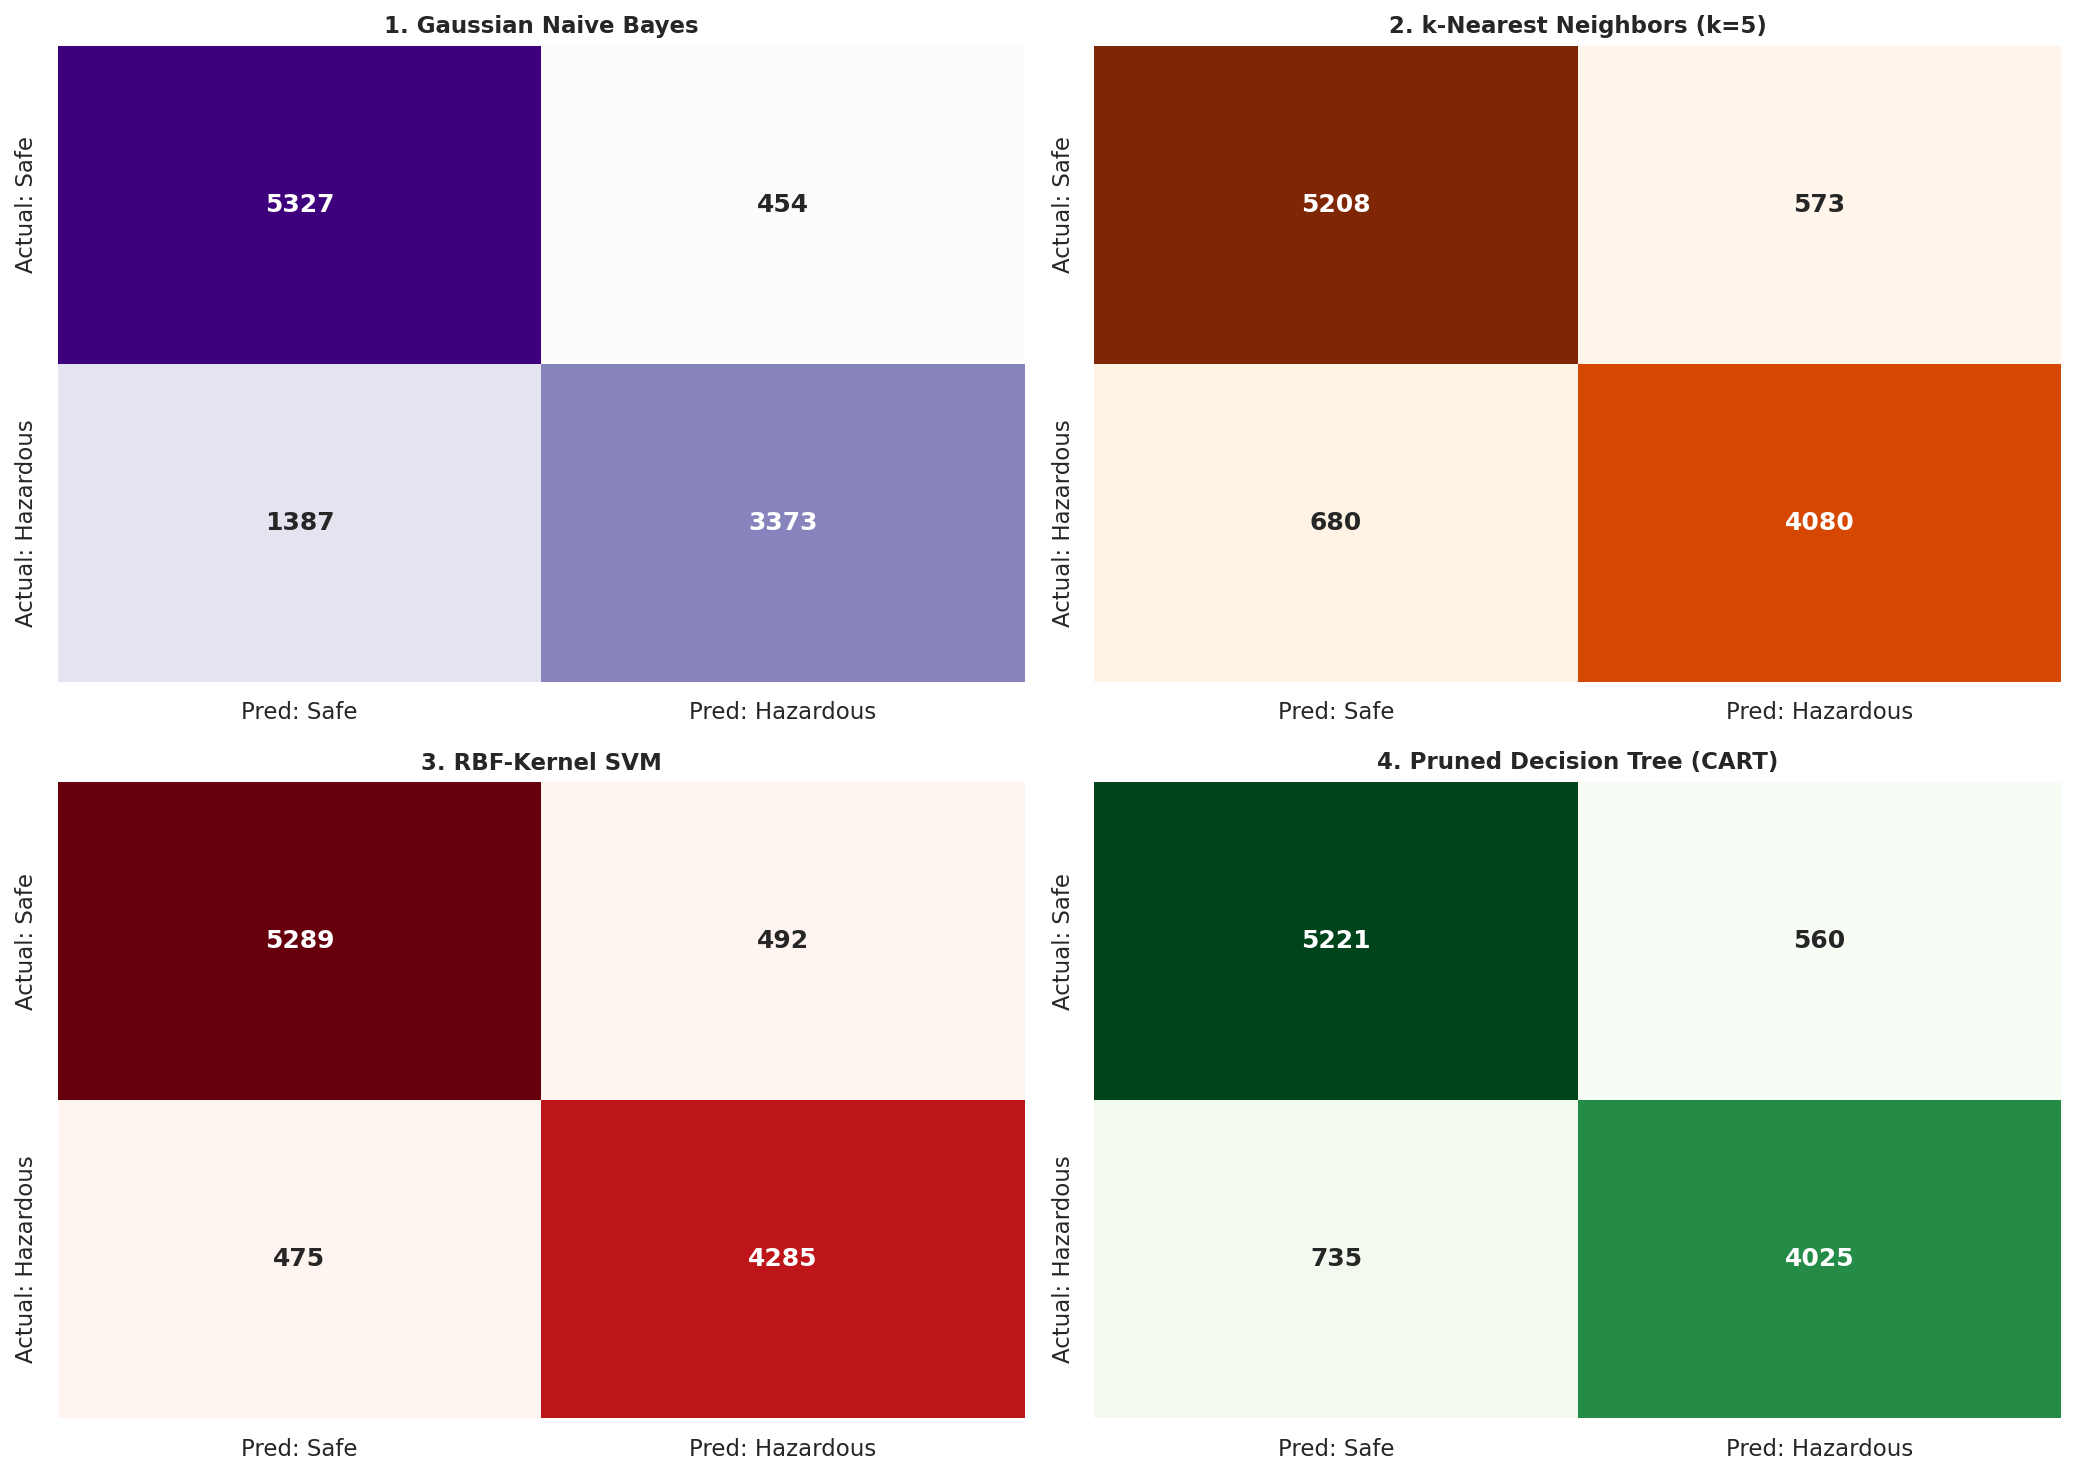

=== CLINICAL RELIABILITY AUDIT (SECTION H: MINIMIZING MISSED HAZARDS) ===


,Model,True Neg (Safe),False Pos (False Alarm),False Neg (Missed Hazard - DANGEROUS),True Pos (Accurate Alert),Sensitivity (Recall),Specificity
0,1. Gaussian Naive Bayes,5327,454,1387,3373,70.86%,92.15%
1,2. k-Nearest Neighbors (k=5),5208,573,680,4080,85.71%,90.09%
2,3. RBF-Kernel SVM,5289,492,475,4285,90.02%,91.49%
3,4. Pruned Decision Tree (CART),5221,560,735,4025,84.56%,90.31%


In [ ]:
# =============================================================================
# Step 6B: Side-by-Side Confusion Matrices & Clinical Error Breakdown
# =============================================================================
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes_flat = axes.ravel()

four_models = [
    ("1. Gaussian Naive Bayes", naive_bayes_library_pipeline, "Purples"),
    ("2. k-Nearest Neighbors (k=5)", knn_library_pipeline, "Oranges"),
    ("3. RBF-Kernel SVM", svm_rbf_library_pipeline, "Reds"),
    ("4. Pruned Decision Tree (CART)", decision_tree_library_pipeline, "Greens")
]

confusion_breakdown = []

for ax, (model_title, pipe, color_map) in zip(axes_flat, four_models):
    y_preds = pipe.predict(X_test)
    cm = confusion_matrix(y_test, y_preds)
    tn, fp, fn, tp = cm.ravel()

    confusion_breakdown.append({
        'Model': model_title,
        'True Neg (Safe)': tn,
        'False Pos (False Alarm)': fp,
        'False Neg (Missed Hazard - DANGEROUS)': fn,
        'True Pos (Accurate Alert)': tp,
        'Sensitivity (Recall)': f"{tp / (tp + fn) * 100:.2f}%",
        'Specificity': f"{tn / (tn + fp) * 100:.2f}%"
    })

    sns.heatmap(
        cm, annot=True, fmt='d', cmap=color_map, cbar=False, ax=ax,
        xticklabels=['Pred: Safe', 'Pred: Hazardous'],
        yticklabels=['Actual: Safe', 'Actual: Hazardous'],
        annot_kws={'size': 12, 'weight': 'bold'}
    )
    ax.set_title(model_title, fontsize=11, weight='bold')

plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'unit4_all_4_confusion_matrices.png'), dpi=300, bbox_inches='tight')
plt.show()

# Display Clinical Diagnostic Table (Medical safety: Minimizing False Negatives)
print("=== CLINICAL RELIABILITY AUDIT (SECTION H: MINIMIZING MISSED HAZARDS) ===")
display(pd.DataFrame(confusion_breakdown))
